# Miniprojeto 2 — Modelagem de Churn com Árvores de Decisão e XGBoost

**Sistemas Inteligentes / Aprendizagem de Máquina — CIn/UFPE**

**Referência teórica:** aulas *Árvores de Decisão & Random Forests* e *Gradient Boosting* do Prof. Germano C.
Vasconcelos (CIn/UFPE) — entropia/Gini e ganho de informação, critérios de parada, pré-poda × pós-poda
(custo-complexidade $R_\alpha(T)=R(T)+\alpha|T|$), navalha de Occam, probabilidade na folha e limiar de decisão,
Random Forests (bagging) e o dilema viés-variância que motiva o boosting.

Este notebook é a continuação do miniprojeto 1 (EDA, consolidação, pré-processamento e imputação).
Ele usa **a coorte principal produzida no miniprojeto 1** (`data/processed/churn_main.csv`) e o
pipeline de preparação já implementado em `scripts/`.

| Item | Decisão |
|---|---|
| Base | 4.976 clientes da coorte principal (≥ 60 dias de histórico no corte de 21/09/2026) |
| Alvo | `churn` = cancelamento em (21/09/2026, 20/11/2026] |
| Split | **70% treino / 30% teste estratificado**, semente 42, feito antes de qualquer ajuste |
| Pré-processamento | Imputação KNN (numéricos) + moda (categóricos) + one-hot, **dentro do `Pipeline`** e reajustado em cada fold |
| Métrica principal | **Recall da classe churn**, garantido pelo **limiar de decisão** (meta ≥ 80%); hiperparâmetros escolhidos por **PR-AUC** (qualidade do ranking da classe churn, independente de limiar) |
| Modelos | Árvore de Decisão (pré-poda × pós-poda × combinada), Random Forest (comparação da aula) e XGBoost (GridSearchCV × Optuna) |

**Roteiro**

1. Configuração e reprodutibilidade
2. Carregamento, split 70/30 e auditoria anti-leakage
3. Base tratada transformada (entregável 3)
4. Linhas de base (baselines)
5. Módulo 1 — Árvore de Decisão (complexidade, pré-poda, pós-poda, regras, importância)
6. Módulo 2 — XGBoost (trade-off `learning_rate`×`n_estimators`, GridSearch, Optuna, restrições monotônicas)
7. Hipóteses autônomas da equipe
8. Escolha do limiar de decisão (recall × precisão × custo)
9. Avaliação final no teste (cego)
10. Análise de overfitting e curvas de aprendizado
11. Relevância de variáveis nos dois modelos
12. Conclusões

## 1. Configuração e reprodutibilidade

* Semente única (`SEED = 42`) para split, validação cruzada, modelos e Optuna.
* Validação cruzada **estratificada 5-fold** dentro do treino; o teste só é usado na Seção 9.
* `Pipeline` com cache (`joblib.Memory`): o pré-processamento de cada fold é calculado uma vez e reutilizado
  entre combinações de hiperparâmetros — mesmo resultado, muito menos tempo.
* Figuras e tabelas são salvas em `reports/` para a apresentação.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / "scripts" / "modeling.py").exists(), "Execute o notebook a partir da raiz do projeto."
os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")
os.environ["PYTHONWARNINGS"] = "ignore"          # silencia avisos também nos processos paralelos
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, optuna
from joblib import Memory
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import (StratifiedKFold, GridSearchCV, cross_validate,
                                     cross_val_predict, learning_curve)
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

from scripts.modeling import (load_main, split_70_30, make_pipeline, feature_names, metrics_at,
                              threshold_for_recall, threshold_min_cost, tree_rules,
                              export_transformed, clean_name, MODELING_DIR)
from scripts.ml_preprocessing import build_ml_preprocessor
from scripts.preprocessing import FEATURE_COLUMNS

SEED = 42
np.random.seed(SEED)
N_JOBS = -1                      # paralelismo da busca (processos)
N_THREADS = os.cpu_count() or 4  # threads do XGBoost quando não há paralelismo externo
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {
    "recall": "recall", "precision": "precision", "f1": "f1",
    "f2": make_scorer(fbeta_score, beta=2), "roc_auc": "roc_auc", "pr_auc": "average_precision",
    "accuracy": "accuracy",
}
CACHE = Memory(location=str(ROOT / ".cache_pipeline"), verbose=0)
REPORTS = ROOT / "reports"; FIG = REPORTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
COR = {"ad": "#2a6f97", "xgb": "#c8553d", "base": "#8d99ae", "ok": "#2a9d8f"}

def salvar(nome):
    plt.savefig(FIG / f"{nome}.png", dpi=150, bbox_inches="tight")

optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | optuna {optuna.__version__}")

Python 3.14.3 | pandas 2.3.3 | numpy 2.5.5 | scikit-learn 1.9.1 | xgboost 3.4.1 | optuna 5.1.0


## 2. Carregamento, split 70/30 estratificado e auditoria anti-leakage

A base de entrada é a coorte principal **determinística** do miniprojeto 1: violações de domínio já viraram
ausências auditadas, mas **nenhuma estatística foi aprendida** nela. Por isso o split vem antes da imputação.

> **Diferença em relação ao slide ilustrativo:** o enunciado cita ~20% de churn como exemplo; a prevalência real
> obtida no miniprojeto 1 é **35,4%** (1.763 churn / 3.213 não-churn). O split mantém essa proporção nas duas partes.

In [2]:
data = load_main()
X_train, X_test, y_train, y_test, ids = split_70_30(data)

resumo = pd.DataFrame({
    "clientes": [len(data), len(X_train), len(X_test)],
    "churn (1)": [data["churn"].sum(), y_train.sum(), y_test.sum()],
    "não churn (0)": [(data["churn"] == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "prevalência": [data["churn"].mean(), y_train.mean(), y_test.mean()],
}, index=["Base completa", "Treino (70%)", "Teste (30%)"])
display(resumo.style.format({"prevalência": "{:.2%}"}))

# Auditoria anti-leakage
assert set(ids["train"]).isdisjoint(ids["test"]), "cliente presente nas duas partições"
assert list(X_train.columns) == list(FEATURE_COLUMNS), "apenas os 10 preditores autorizados"
proibidas = {"id_cliente", "data_ocorrencia_churn", "churn", "coorte", "data_corte"}
assert proibidas.isdisjoint(X_train.columns)
print("OK: sem clientes em comum, sem identificadores/datas/alvo entre os preditores.")
print("\nAusências por partição (serão imputadas DENTRO do pipeline):")
display(pd.DataFrame({"treino": X_train.isna().sum(), "teste": X_test.isna().sum()}).query("treino + teste > 0"))

,clientes,churn (1),não churn (0),prevalência
Base completa,4976,1763,3213,35.43%
Treino (70%),3483,1234,2249,35.43%
Teste (30%),1493,529,964,35.43%


OK: sem clientes em comum, sem identificadores/datas/alvo entre os preditores.

Ausências por partição (serão imputadas DENTRO do pipeline):


,treino,teste
mensalidade_rs,94,38
atrasos_6m,31,12
chamados_30d,17,6
chamados_60d,17,6
chamados_90d,17,6
tipo_contrato,17,8
forma_pagamento,14,6


## 3. Base tratada transformada (entregável 3)

O CSV abaixo é a base usada diretamente no treino/teste: **pré-processamento ajustado somente no treino** e
apenas `transform` no teste. Ele contém `id_cliente`, `partition` (train/test), os 14 atributos codificados,
as flags `imputed_*` (proveniência de cada célula imputada) e o alvo.

O mesmo arquivo pode ser regenerado sem o notebook: `python -m scripts.run_modeling`.

> Para **modelar**, usamos o `Pipeline` sobre os dados brutos, porque assim a imputação é reajustada dentro de
> cada fold da validação cruzada. Fazer CV diretamente sobre o CSV exportado vazaria estatísticas
> (medianas/vizinhos) do fold de validação para o de treino.

In [3]:
prep_export = build_ml_preprocessor(numeric_imputation="knn").set_output(transform="pandas")
base_transformada = export_transformed(prep_export, X_train, X_test, y_train, y_test, ids,
                                       MODELING_DIR / "churn_transformed_70_30.csv")
print("Formato:", base_transformada.shape, "| ausências restantes:", int(base_transformada.isna().sum().sum()))
print(base_transformada.groupby("partition")["churn"].agg(clientes="size", prevalencia="mean"))
base_transformada.head()

Formato: (4976, 27) | ausências restantes: 0
           clientes  prevalencia
partition                       
test           1493     0.354320
train          3483     0.354292


,id_cliente,partition,tempo_cliente_meses,mensalidade_rs,atrasos_6m,chamados_30d,chamados_60d,chamados_90d,tipo_contrato_Anual,tipo_contrato_Bienal,...,imputed_mensalidade_rs,imputed_atrasos_6m,imputed_chamados_30d,imputed_chamados_60d,imputed_chamados_90d,imputed_tipo_contrato,imputed_forma_pagamento,imputed_fibra_optica,imputed_debito_automatico,churn
0,C0851,train,11.0,98.77,1.0,2.0,3.0,4.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,1
1,C4753,train,10.0,64.84,1.0,1.0,2.0,2.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,1
2,C0304,train,23.0,64.28,0.0,0.0,1.0,3.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,C2407,train,28.0,49.98,0.0,0.0,1.0,1.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,C1778,train,38.0,68.96,1.0,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


## 4. Linhas de base

Antes de otimizar, medimos referências: classificadores ingênuos (que não aprendem nada), uma árvore **sem nenhuma
restrição** e o XGBoost com hiperparâmetros padrão. Todas as métricas abaixo são de **validação cruzada no treino**
(média dos 5 folds), com a métrica de treino ao lado para medir o *gap* (overfitting).

In [4]:
def cv_resumo(nome, estimador, X=None, y=None):
    X = X_train if X is None else X; y = y_train if y is None else y
    r = cross_validate(estimador, X, y, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=N_JOBS)
    linha = {"modelo": nome}
    for m in SCORING:
        linha[f"val_{m}"] = r[f"test_{m}"].mean()
        linha[f"treino_{m}"] = r[f"train_{m}"].mean()
    linha["val_f2_std"] = r["test_f2"].std()
    linha["val_pr_auc_std"] = r["test_pr_auc"].std()
    linha["gap_recall"] = linha["treino_recall"] - linha["val_recall"]
    linha["gap_auc"] = linha["treino_roc_auc"] - linha["val_roc_auc"]
    return linha

COLS = ["modelo", "val_recall", "val_precision", "val_f1", "val_f2", "val_roc_auc", "val_pr_auc",
        "treino_recall", "treino_roc_auc", "gap_recall", "gap_auc"]
def mostrar(linhas):
    return pd.DataFrame(linhas)[COLS].set_index("modelo").round(3)

RESULTADOS_CV = []
SPW = (y_train == 0).sum() / (y_train == 1).sum()   # razão negativos/positivos ≈ 1,82
baselines = {
    "Dummy (sempre não-churn)": DummyClassifier(strategy="most_frequent"),
    "Dummy (sempre churn)": DummyClassifier(strategy="constant", constant=1),
    "Dummy (aleatório estratificado)": DummyClassifier(strategy="stratified", random_state=SEED),
    "AD sem poda": DecisionTreeClassifier(random_state=SEED),
    "XGB padrão": XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="logloss"),
}
for nome, est in baselines.items():
    RESULTADOS_CV.append(cv_resumo(nome, make_pipeline(est, memory=CACHE)))
mostrar(RESULTADOS_CV)

,val_recall,val_precision,val_f1,val_f2,val_roc_auc,val_pr_auc,treino_recall,treino_roc_auc,gap_recall,gap_auc
modelo,,,,,,,,,,
Dummy (sempre não-churn),0.000,0.000,0.000,0.000,0.500,0.354,0.000,0.500,0.000,0.000
Dummy (sempre churn),1.000,0.354,0.523,0.733,0.500,0.354,1.000,0.500,0.000,0.000
Dummy (aleatório estratificado),0.335,0.350,0.342,0.338,0.497,0.353,0.358,0.505,0.023,0.008
AD sem poda,0.491,0.489,0.490,0.491,0.604,0.421,1.000,1.000,0.509,0.396
XGB padrão,0.524,0.585,0.553,0.535,0.747,0.609,0.929,0.996,0.405,0.249


**Leitura das baselines**

* "Sempre churn" tem recall 1,0 mas precisão de 35%: **otimizar recall isoladamente é trivial e inútil**.
* **Achado importante:** com prevalência de 35%, esse classificador trivial tem **F2 ≈ 0,73** — maior que o de modelos
  razoáveis. Numa primeira versão otimizamos F2 e a busca convergiu para modelos que marcavam quase todos como churn
  (recall 0,96, precisão 0,44). Por isso **separamos as duas decisões**:
  1. **Hiperparâmetros → PR-AUC** (área sob a curva precisão-recall da classe churn): mede a qualidade do *ranking* de
     risco, não depende de limiar e o trivial vale só 0,354 (a prevalência).
  2. **Recall → limiar de decisão** (Seção 8): escolhido em previsões *out-of-fold* do treino para atingir recall ≥ 80%.
     Assim os modelos são comparados **no mesmo recall**, e vence quem tem mais precisão (menos ofertas desperdiçadas).
* A árvore sem poda memoriza o treino (recall e AUC de treino = 1,0) e generaliza mal (AUC de validação ≈ 0,60):
  é o caso clássico de **overfitting** que as seções seguintes corrigem.
* O XGBoost padrão também tem *gap* grande; os hiperparâmetros de regularização serão decisivos.

## 5. Módulo 1 — Árvore de Decisão

### 5.1 Curva de complexidade: onde a árvore começa a memorizar ruído?

Variamos `max_depth` de 1 a 20 (e sem limite), com e sem `class_weight="balanced"`, e comparamos treino × validação.

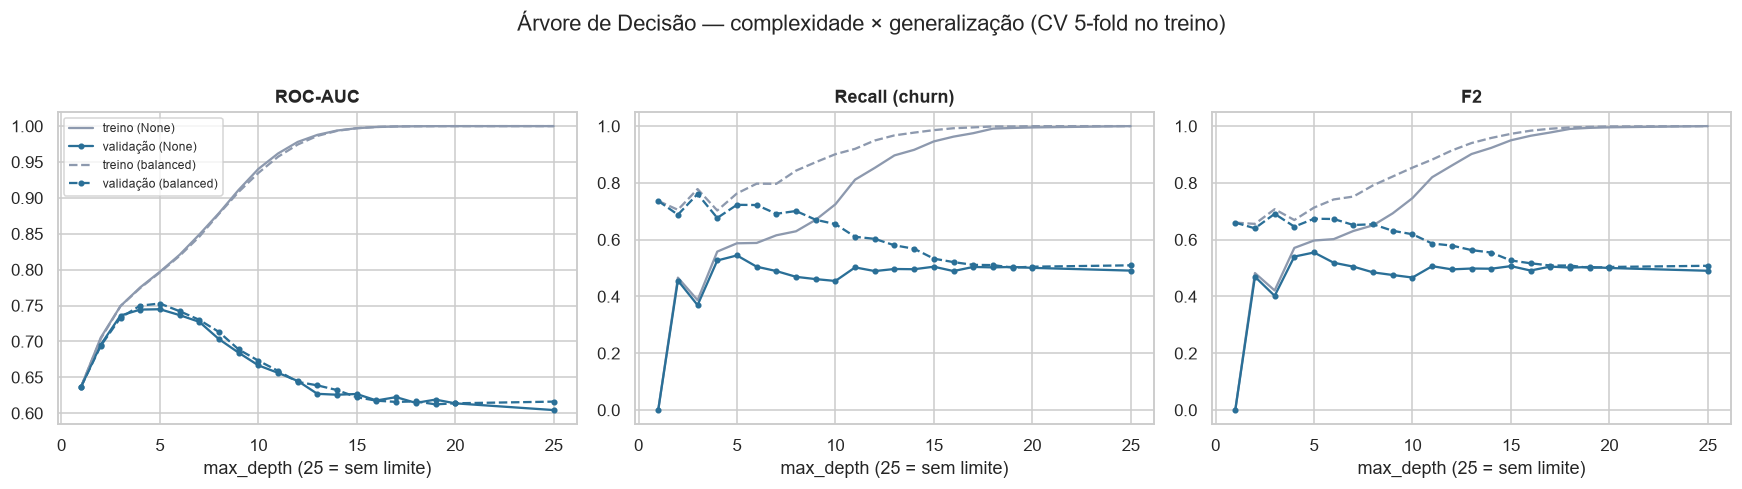

Maior AUC de validação: max_depth=5 (balanced) → AUC val 0.753 vs treino 0.796


In [5]:
profundidades = list(range(1, 21)) + [None]
curva = []
for cw in [None, "balanced"]:
    for d in profundidades:
        pipe = make_pipeline(DecisionTreeClassifier(max_depth=d, class_weight=cw, random_state=SEED), memory=CACHE)
        r = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=N_JOBS)
        curva.append({"class_weight": str(cw), "max_depth": 25 if d is None else d,
                      **{f"{p}_{m}": r[f"{'test' if p == 'val' else 'train'}_{m}"].mean()
                         for p in ["val", "treino"] for m in ["recall", "roc_auc", "f2"]}})
curva = pd.DataFrame(curva)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, m, titulo in zip(axes, ["roc_auc", "recall", "f2"], ["ROC-AUC", "Recall (churn)", "F2"]):
    for cw, estilo in [("None", "-"), ("balanced", "--")]:
        c = curva[curva["class_weight"] == cw]
        ax.plot(c["max_depth"], c[f"treino_{m}"], estilo, color=COR["base"], label=f"treino ({cw})")
        ax.plot(c["max_depth"], c[f"val_{m}"], estilo, color=COR["ad"], marker="o", ms=3, label=f"validação ({cw})")
    ax.set(title=titulo, xlabel="max_depth (25 = sem limite)")
axes[0].legend(fontsize=8)
plt.suptitle("Árvore de Decisão — complexidade × generalização (CV 5-fold no treino)", y=1.03)
plt.tight_layout(); salvar("ad_curva_complexidade"); plt.show()

melhor_d = curva.loc[curva["val_roc_auc"].idxmax()]
print(f"Maior AUC de validação: max_depth={int(melhor_d.max_depth)} ({melhor_d.class_weight}) "
      f"→ AUC val {melhor_d.val_roc_auc:.3f} vs treino {melhor_d.treino_roc_auc:.3f}")

A validação atinge o máximo em árvores rasas (profundidade ~4–6) e depois cai enquanto o treino continua subindo:
a partir daí a árvore passa a **memorizar ruído**. `class_weight="balanced"` desloca o recall para cima sem alterar
a capacidade de ordenação (AUC) — ele muda o ponto de operação, não o modelo em si.

### 5.2 Pré-poda (parada antecipada) — GridSearchCV em duas etapas

**Justificativa do espaço de busca** (definido pela equipe a partir da curva acima e do tamanho da amostra):

| Hiperparâmetro | Valores | Racional |
|---|---|---|
| `criterion` | gini, entropy | Gini (CART) $=1-\sum p_i^2$ dispensa log; entropia (ID3/C4.5) $=-\sum p_i\log_2 p_i$ — a aula observa que decidem igual na grande maioria dos casos; testamos se isso vale aqui |
| `max_depth` | 3, 4, 5, 6, 7, 8, 10 | a curva mostra pico em 4–6; 10 serve de controle de overfitting |
| `min_samples_leaf` | 1, 10, 25, 50, 100 | com ~2.800 clientes por fold, 100 ≈ 3,6% → folhas estatisticamente estáveis |
| `min_samples_split` | 2, 50, 100 | impede divisões em nós pequenos |
| `class_weight` | None, balanced | compensa a classe minoritária (35%) diretamente no critério de divisão |
| **Etapa 2:** `max_leaf_nodes` | 8 … 64, None | limita a árvore pelo nº de regras (interpretabilidade) |
| **Etapa 2:** `min_impurity_decrease` | 0 … 0,005 | só divide se o ganho de pureza compensar |
| **Etapa 2:** `max_features` | None, 0,8, sqrt | aleatoriedade nas divisões (além do pedido no enunciado) |

Critério de seleção (`refit`): **PR-AUC média de validação** (F2, recall, precisão e ROC-AUC também são registrados).

In [6]:
pipe_ad = make_pipeline(DecisionTreeClassifier(random_state=SEED), memory=CACHE)
grade_pre1 = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 4, 5, 6, 7, 8, 10],
    "model__min_samples_leaf": [1, 10, 25, 50, 100],
    "model__min_samples_split": [2, 50, 100],
    "model__class_weight": [None, "balanced"],
}
t0 = time.time()
gs_pre1 = GridSearchCV(pipe_ad, grade_pre1, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=N_JOBS,
                       return_train_score=True).fit(X_train, y_train)
t_pre1 = time.time() - t0

def top(gs, k=8):
    res = pd.DataFrame(gs.cv_results_)
    pcols = [c for c in res if c.startswith("param_")]
    out = res[pcols + ["mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc", "mean_test_recall",
                       "mean_test_precision", "mean_train_pr_auc", "mean_train_roc_auc"]]
    out = out.sort_values(["mean_test_pr_auc", "mean_test_roc_auc"], ascending=False).head(k)
    out.columns = [c.replace("param_model__", "").replace("mean_", "") for c in out.columns]
    return out.round(3).reset_index(drop=True)

print(f"Etapa 1: {len(gs_pre1.cv_results_['params'])} combinações × 5 folds em {t_pre1:.0f}s")
top(gs_pre1)

Etapa 1: 420 combinações × 5 folds em 158s


,class_weight,criterion,max_depth,min_samples_leaf,min_samples_split,test_pr_auc,std_test_pr_auc,test_roc_auc,test_recall,test_precision,train_pr_auc,train_roc_auc
0,balanced,entropy,7,25,2,0.614,0.012,0.758,0.718,0.541,0.694,0.818
1,balanced,entropy,7,25,50,0.614,0.012,0.758,0.718,0.541,0.694,0.818
2,None,gini,6,25,100,0.613,0.016,0.753,0.459,0.621,0.669,0.802
3,balanced,gini,10,1,100,0.613,0.014,0.753,0.720,0.552,0.704,0.822
4,None,gini,7,50,2,0.612,0.019,0.755,0.494,0.625,0.672,0.802
5,None,gini,7,50,50,0.612,0.019,0.755,0.494,0.625,0.672,0.802
6,None,gini,7,50,100,0.612,0.019,0.755,0.494,0.625,0.672,0.802
7,None,entropy,8,50,2,0.612,0.011,0.757,0.485,0.620,0.674,0.802


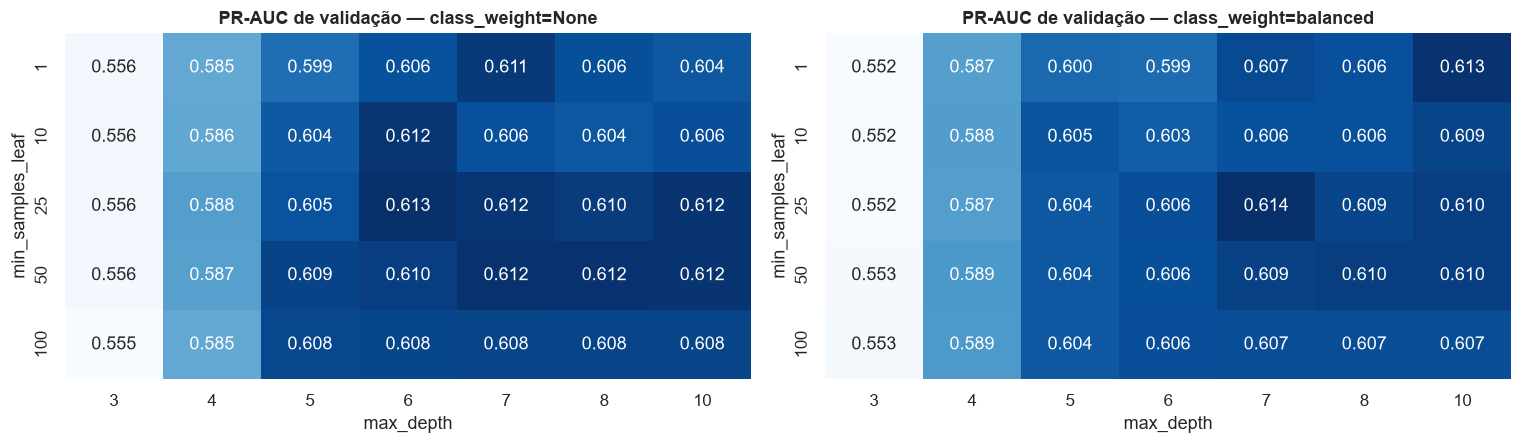

In [7]:
res1 = pd.DataFrame(gs_pre1.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, cw in zip(axes, ["None", "balanced"]):
    sub = res1[res1["param_model__class_weight"].astype(str) == cw]
    piv = sub.pivot_table(index="param_model__min_samples_leaf", columns="param_model__max_depth",
                          values="mean_test_pr_auc", aggfunc="max")
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", ax=ax, cbar=False)
    ax.set(title=f"PR-AUC de validação — class_weight={cw}", xlabel="max_depth", ylabel="min_samples_leaf")
plt.tight_layout(); salvar("ad_prepoda_heatmap"); plt.show()

In [8]:
best1 = {k.replace("model__", ""): v for k, v in gs_pre1.best_params_.items()}
grade_pre2 = {
    "model__max_leaf_nodes": [8, 12, 16, 24, 32, 48, 64, None],
    "model__min_impurity_decrease": [0.0, 0.0005, 0.001, 0.002, 0.005],
    "model__max_features": [None, 0.8, "sqrt"],
}
pipe_ad2 = make_pipeline(DecisionTreeClassifier(random_state=SEED, **best1), memory=CACHE)
t0 = time.time()
gs_pre2 = GridSearchCV(pipe_ad2, grade_pre2, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=N_JOBS,
                       return_train_score=True).fit(X_train, y_train)
t_pre2 = time.time() - t0
print("Melhor etapa 1:", best1, f"→ PR-AUC {gs_pre1.best_score_:.4f}")
print(f"Etapa 2 ({time.time()-t0:.0f}s): melhor PR-AUC {gs_pre2.best_score_:.4f} com {gs_pre2.best_params_}")

# Fica com a etapa 2 somente se ela melhorar a PR-AUC de validação
gs_pre = gs_pre2 if gs_pre2.best_score_ > gs_pre1.best_score_ else gs_pre1
AD_PRE = gs_pre.best_estimator_
params_pre = {**best1, **({k.replace("model__", ""): v for k, v in gs_pre2.best_params_.items()}
                          if gs_pre is gs_pre2 else {})}
print("\nÁrvore PRÉ-PODA escolhida:", params_pre)
print(f"Folhas: {AD_PRE[-1].get_n_leaves()} | profundidade: {AD_PRE[-1].get_depth()}")
top(gs_pre2, 5)

Melhor etapa 1: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 25, 'min_samples_split': 2} → PR-AUC 0.6136
Etapa 2 (42s): melhor PR-AUC 0.6136 com {'model__max_features': None, 'model__max_leaf_nodes': None, 'model__min_impurity_decrease': 0.0}

Árvore PRÉ-PODA escolhida: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 25, 'min_samples_split': 2}
Folhas: 72 | profundidade: 7


,max_features,max_leaf_nodes,min_impurity_decrease,test_pr_auc,std_test_pr_auc,test_roc_auc,test_recall,test_precision,train_pr_auc,train_roc_auc
0,None,None,0.000,0.614,0.012,0.758,0.718,0.541,0.694,0.818
1,None,64,0.000,0.614,0.012,0.758,0.717,0.541,0.694,0.818
2,0.8,48,0.001,0.613,0.025,0.753,0.698,0.544,0.677,0.809
3,0.8,48,0.000,0.613,0.025,0.753,0.703,0.540,0.682,0.812
4,0.8,48,0.000,0.613,0.025,0.753,0.703,0.540,0.682,0.812


### 5.3 Pós-poda por complexidade de custo (`ccp_alpha`)

Aqui a árvore cresce **sem restrições** (memoriza o treino) e depois é podada de baixo para cima (*bottom-up*):
cada `ccp_alpha` remove os ramos cujo ganho não compensa o custo de complexidade
$R_\alpha(T) = R(T) + \alpha\,|T_{folhas}|$ — o mecanismo de **penalização por folhas** do CART (Breiman et al., 1984)
visto em aula.

* Os valores candidatos de α vêm do caminho de poda (`cost_complexity_pruning_path`) calculado **apenas no treino**
  (com e sem `class_weight`); usamos 40 quantis desse caminho.
* A escolha de α é feita pela mesma CV 5-fold (PR-AUC), garantindo comparação justa com a pré-poda.

In [9]:
prep_tr = build_ml_preprocessor(numeric_imputation="knn").set_output(transform="pandas").fit(X_train, y_train)
Xtr_t = prep_tr.transform(X_train)

caminhos, candidatos = {}, []
for cw in [None, "balanced"]:
    path = DecisionTreeClassifier(random_state=SEED, class_weight=cw).cost_complexity_pruning_path(Xtr_t, y_train)
    caminhos[str(cw)] = path
    alphas = path.ccp_alphas[:-1]                  # o último α poda até a raiz
    candidatos += list(np.quantile(alphas, np.linspace(0, 1, 40)))
candidatos = np.unique(np.round(candidatos, 7))
print(f"Caminho de poda: {len(caminhos['None'].ccp_alphas)} α (None) e "
      f"{len(caminhos['balanced'].ccp_alphas)} α (balanced); {len(candidatos)} candidatos testados")

t0 = time.time()
gs_pos = GridSearchCV(pipe_ad, {"model__ccp_alpha": candidatos, "model__class_weight": [None, "balanced"]},
                      scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=N_JOBS, return_train_score=True
                      ).fit(X_train, y_train)
t_pos = time.time() - t0
AD_POS = gs_pos.best_estimator_
params_pos = {k.replace("model__", ""): v for k, v in gs_pos.best_params_.items()}
print(f"Árvore PÓS-PODA ({t_pos:.0f}s): {params_pos} → PR-AUC val {gs_pos.best_score_:.4f}")
print(f"Folhas: {AD_POS[-1].get_n_leaves()} | profundidade: {AD_POS[-1].get_depth()}")

Caminho de poda: 372 α (None) e 477 α (balanced); 72 candidatos testados


Árvore PÓS-PODA (51s): {'ccp_alpha': np.float64(0.0018582), 'class_weight': 'balanced'} → PR-AUC val 0.5873
Folhas: 15 | profundidade: 5


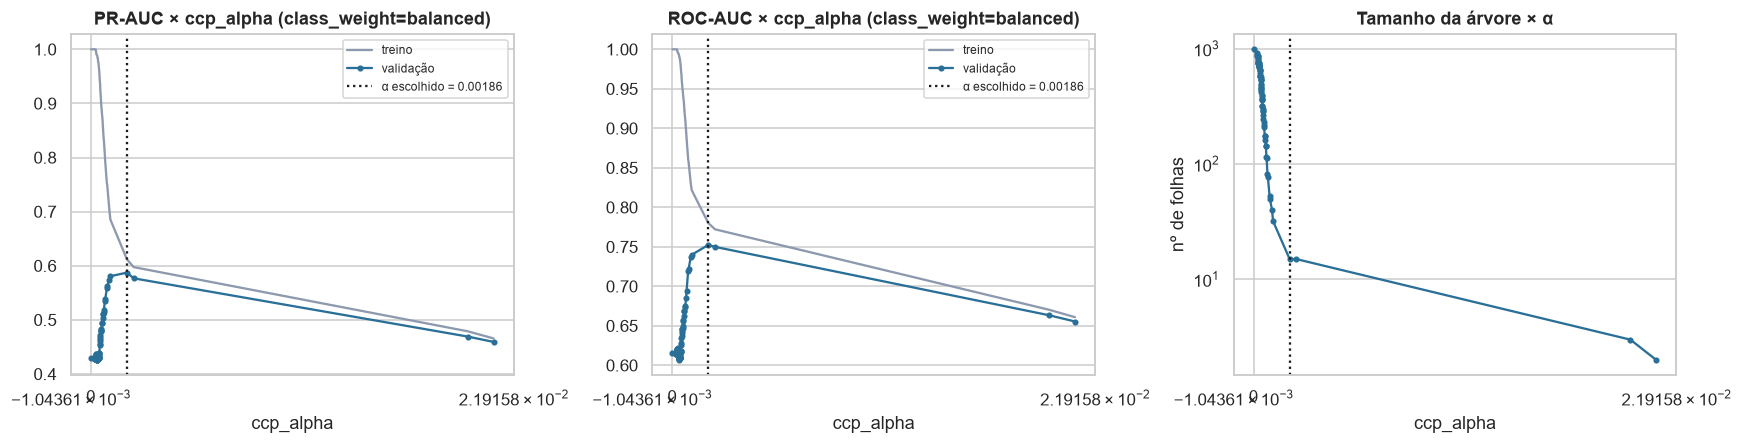

In [10]:
res_pos = pd.DataFrame(gs_pos.cv_results_)
cw_best = str(params_pos["class_weight"])
sub = res_pos[res_pos["param_model__class_weight"].astype(str) == cw_best].sort_values("param_model__ccp_alpha")
alphas_plot = sub["param_model__ccp_alpha"].astype(float).values
folhas = [DecisionTreeClassifier(random_state=SEED, ccp_alpha=a, class_weight=params_pos["class_weight"])
          .fit(Xtr_t, y_train).get_n_leaves() for a in alphas_plot]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, m, tit in zip(axes[:2], ["pr_auc", "roc_auc"], ["PR-AUC", "ROC-AUC"]):
    ax.plot(alphas_plot, sub[f"mean_train_{m}"], color=COR["base"], label="treino")
    ax.plot(alphas_plot, sub[f"mean_test_{m}"], color=COR["ad"], marker="o", ms=3, label="validação")
    ax.axvline(params_pos["ccp_alpha"], ls=":", color="k", label=f"α escolhido = {params_pos['ccp_alpha']:.5f}")
    ax.set(xscale="symlog", xlabel="ccp_alpha", title=f"{tit} × ccp_alpha (class_weight={cw_best})"); ax.legend(fontsize=8)
axes[2].plot(alphas_plot, folhas, color=COR["ad"], marker="o", ms=3)
axes[2].axvline(params_pos["ccp_alpha"], ls=":", color="k")
axes[2].set(xscale="symlog", yscale="log", xlabel="ccp_alpha", ylabel="nº de folhas", title="Tamanho da árvore × α")
plt.tight_layout(); salvar("ad_pospoda_ccp_alpha"); plt.show()

**Reproduzindo o gráfico da aula "Variação do Erro com o Número de Nós"** com os nossos dados: cada ponto é uma
árvore do caminho de poda; o erro (1 − acurácia) de treino cai sempre, o de validação tem um mínimo e depois sobe —
o ponto ótimo de poda.

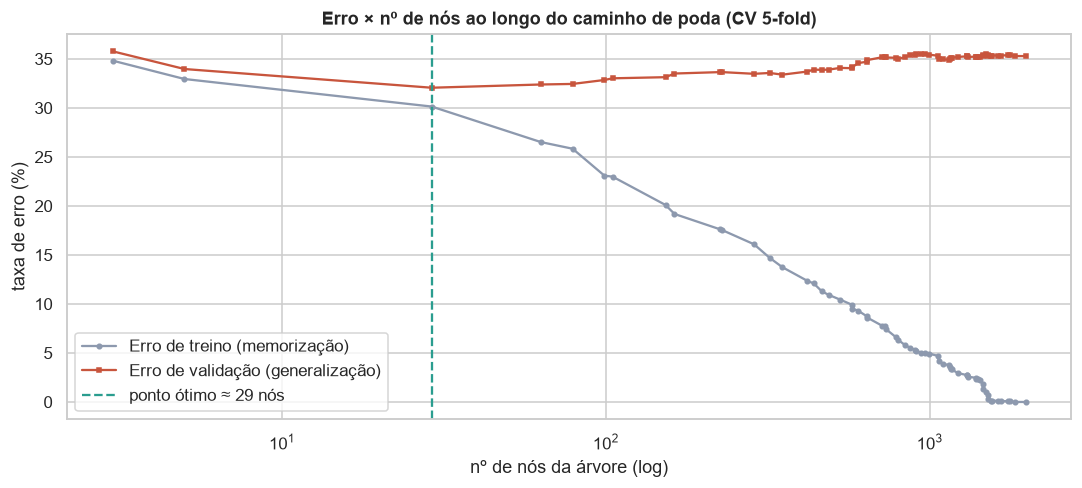

Menor erro de validação: 32.1% com 29 nós; árvore completa: 35.3% com 1981 nós


In [11]:
nos = [DecisionTreeClassifier(random_state=SEED, ccp_alpha=a, class_weight=params_pos["class_weight"])
       .fit(Xtr_t, y_train).tree_.node_count for a in alphas_plot]
erro = pd.DataFrame({"nos": nos, "treino": 1 - sub["mean_train_accuracy"].values,
                     "validacao": 1 - sub["mean_test_accuracy"].values}).sort_values("nos")
erro = erro.groupby("nos", as_index=False).mean()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(erro["nos"], 100 * erro["treino"], color=COR["base"], marker="o", ms=3, label="Erro de treino (memorização)")
ax.plot(erro["nos"], 100 * erro["validacao"], color=COR["xgb"], marker="s", ms=3, label="Erro de validação (generalização)")
otimo = erro.loc[erro["validacao"].idxmin()]
ax.axvline(otimo["nos"], ls="--", color=COR["ok"], label=f"ponto ótimo ≈ {int(otimo['nos'])} nós")
ax.set(xscale="log", xlabel="nº de nós da árvore (log)", ylabel="taxa de erro (%)",
       title="Erro × nº de nós ao longo do caminho de poda (CV 5-fold)")
ax.legend(); plt.tight_layout(); salvar("ad_erro_vs_nos"); plt.show()
print(f"Menor erro de validação: {100*otimo['validacao']:.1f}% com {int(otimo['nos'])} nós; "
      f"árvore completa: {100*erro['validacao'].iloc[-1]:.1f}% com {int(erro['nos'].iloc[-1])} nós")

### 5.3b Combinação pré + pós-poda (recomendação prática da aula)

O quadro-síntese da aula recomenda **combinar `max_depth` + `ccp_alpha`**: limites básicos de crescimento e pós-poda
ajustada por validação. Testamos essa terceira variante com a mesma CV.

In [12]:
grade_comb = {"model__max_depth": [4, 5, 6, 8], "model__min_samples_leaf": [1, 25],
              "model__ccp_alpha": candidatos[::3], "model__class_weight": [None, "balanced"]}
t0 = time.time()
gs_comb = GridSearchCV(pipe_ad, grade_comb, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=N_JOBS,
                       return_train_score=True).fit(X_train, y_train)
t_comb = time.time() - t0
AD_COMB = gs_comb.best_estimator_
params_comb = {k.replace("model__", ""): v for k, v in gs_comb.best_params_.items()}
print(f"Árvore COMBINADA ({t_comb:.0f}s, {len(gs_comb.cv_results_['params'])} combinações): {params_comb} "
      f"→ PR-AUC val {gs_comb.best_score_:.4f}")
print(f"Folhas: {AD_COMB[-1].get_n_leaves()} | profundidade: {AD_COMB[-1].get_depth()}")

Árvore COMBINADA (140s, 384 combinações): {'ccp_alpha': np.float64(0.0), 'class_weight': None, 'max_depth': 6, 'min_samples_leaf': 25} → PR-AUC val 0.6087
Folhas: 51 | profundidade: 6


### 5.4 Pré-poda × pós-poda × combinada

Comparação na **validação cruzada** (base da escolha) e em complexidade. Regra de decisão definida antes de olhar o
teste: entre as árvores a menos de 0,005 da melhor PR-AUC de validação, vence a de **menos folhas** — a
**navalha de Occam** da aula (uma hipótese simples que explica os dados dificilmente é coincidência).

In [13]:
RESULTADOS_CV.append(cv_resumo("AD pré-poda", AD_PRE))
RESULTADOS_CV.append(cv_resumo("AD pós-poda (ccp_alpha)", AD_POS))
RESULTADOS_CV.append(cv_resumo("AD pré + pós (combinada)", AD_COMB))
VARIANTES = {"AD pré-poda": AD_PRE, "AD pós-poda (ccp_alpha)": AD_POS, "AD pré + pós (combinada)": AD_COMB}
comp = mostrar([r for r in RESULTADOS_CV if r["modelo"] in ["AD sem poda", *VARIANTES]])
ad_livre = make_pipeline(DecisionTreeClassifier(random_state=SEED)).fit(X_train, y_train)[-1]
arvores = [ad_livre] + [m[-1] for m in VARIANTES.values()]
comp["folhas"] = [m.get_n_leaves() for m in arvores]
comp["profundidade"] = [m.get_depth() for m in arvores]
comp["tempo_busca_s"] = [np.nan, t_pre1 + t_pre2, t_pos, t_comb]
display(comp)

melhor = comp.loc[list(VARIANTES), "val_pr_auc"].max()
empatadas = comp.loc[list(VARIANTES)].query("val_pr_auc >= @melhor - 0.005")
AD_FINAL_NOME = empatadas["folhas"].idxmin()
AD_FINAL = VARIANTES[AD_FINAL_NOME]
print("Dentro da margem de 0,005 da melhor PR-AUC:", list(empatadas.index))
print(f"Árvore escolhida para as próximas seções: {AD_FINAL_NOME} "
      f"({AD_FINAL[-1].get_n_leaves()} folhas, profundidade {AD_FINAL[-1].get_depth()})")

,val_recall,val_precision,val_f1,val_f2,val_roc_auc,val_pr_auc,treino_recall,treino_roc_auc,gap_recall,gap_auc,folhas,profundidade,tempo_busca_s
modelo,,,,,,,,,,,,,
AD sem poda,0.491,0.489,0.490,0.491,0.604,0.421,1.000,1.000,0.509,0.396,916,22,NaN
AD pré-poda,0.718,0.541,0.616,0.673,0.758,0.614,0.780,0.818,0.062,0.059,72,7,199.722787
AD pós-poda (ccp_alpha),0.725,0.535,0.615,0.676,0.752,0.587,0.756,0.780,0.030,0.028,15,5,50.948040
AD pré + pós (combinada),0.474,0.611,0.533,0.496,0.748,0.609,0.533,0.809,0.059,0.061,51,6,140.091834


Dentro da margem de 0,005 da melhor PR-AUC: ['AD pré-poda', 'AD pré + pós (combinada)']
Árvore escolhida para as próximas seções: AD pré + pós (combinada) (51 folhas, profundidade 6)


### 5.5 Extração de regras SE-ENTÃO

Cada percurso raiz → folha é uma regra de classificação (aula). As regras são lidas na **escala original** dos
atributos (árvores dispensam padronização).

* **P(churn | regra) = clientes com churn na folha ÷ clientes na folha**, contados no treino — a definição de
  probabilidade da árvore vista em aula.
* **Cuidado que identificamos:** com `class_weight="balanced"`, os valores internos da árvore (e o desenho do
  `plot_tree`) ficam *ponderados* e superestimam a taxa de churn. Por isso as tabelas abaixo usam as **contagens reais**
  de clientes (`decision_path`), e não `tree_.value`.
* Seguindo a aula, apresentamos **perfis de churn (alto risco)** e **perfis de permanência (retenção)**.

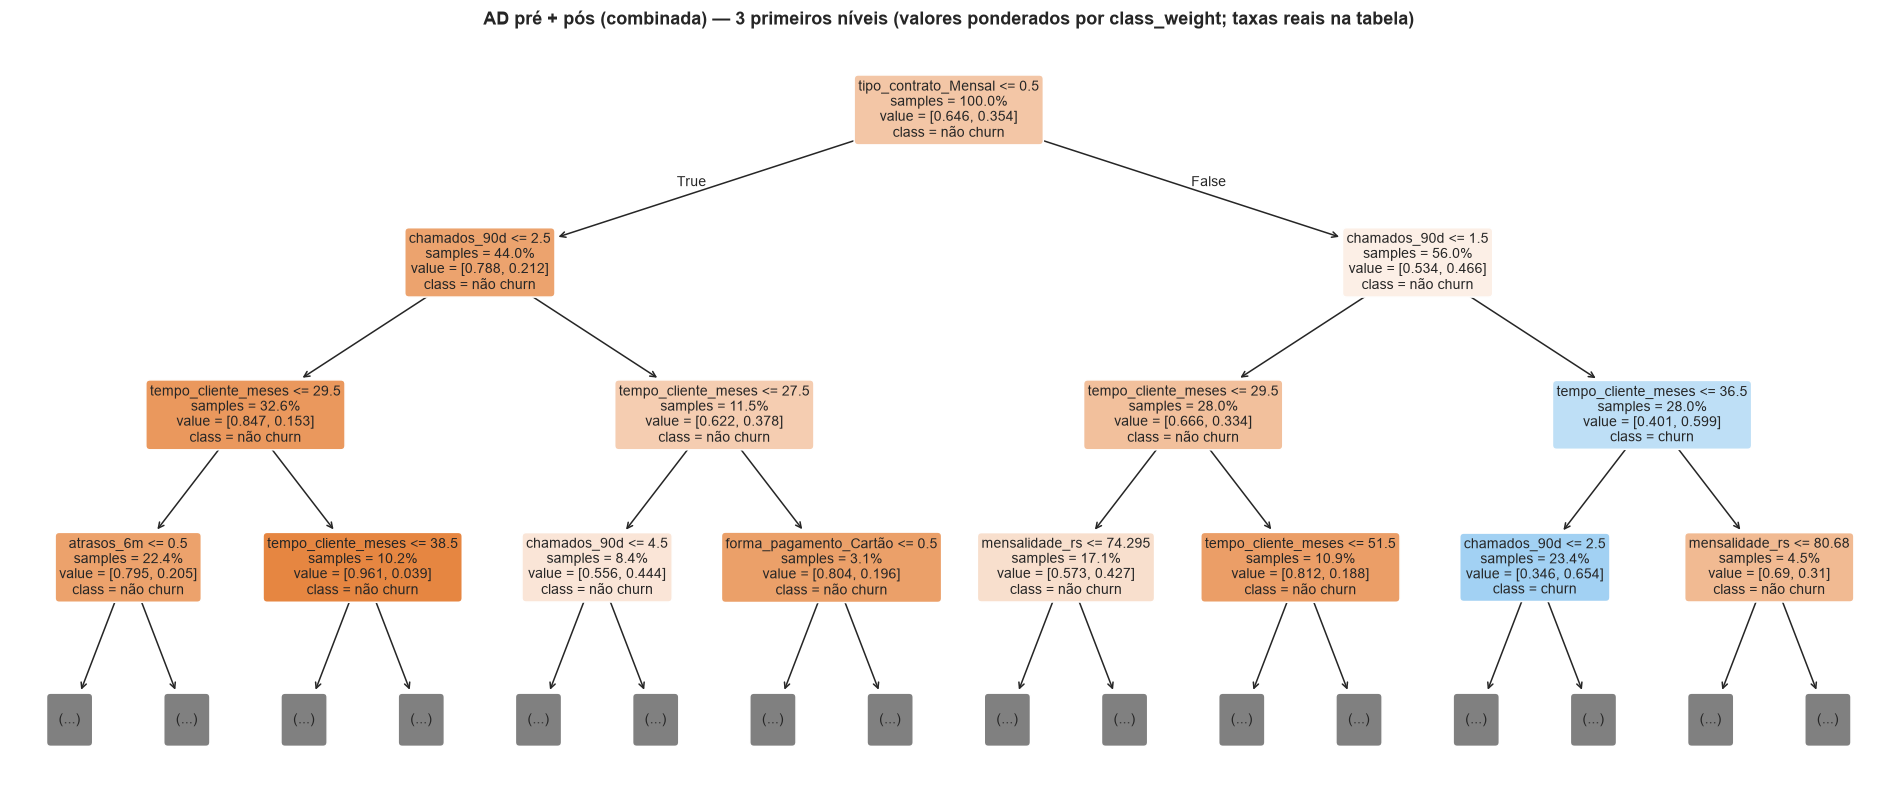

|--- tipo_contrato_Mensal <= 0.50
|   |--- chamados_90d <= 2.50
|   |   |--- tempo_cliente_meses <= 29.50
|   |   |   |--- atrasos_6m <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- atrasos_6m >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- tempo_cliente_meses >  29.50
|   |   |   |--- tempo_cliente_meses <= 38.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- tempo_cliente_meses >  38.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- chamados_90d >  2.50
|   |   |--- tempo_cliente_meses <= 27.50
|   |   |   |--- chamados_90d <= 4.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- chamados_90d >  4.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- tempo_cliente_meses >  27.50
|   |   |   |--- forma_pagamento_Cartão <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- forma_pagamento_Cartão >  0.50
|   |   |   |   |--- class: 0
|--- tipo_contrato_Mensal >  

In [14]:
nomes = feature_names(AD_FINAL)
arvore = AD_FINAL[-1]
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arvore, max_depth=3, feature_names=nomes, class_names=["não churn", "churn"], filled=True,
          rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title(f"{AD_FINAL_NOME} — 3 primeiros níveis (valores ponderados por class_weight; taxas reais na tabela)")
salvar("ad_arvore_topo"); plt.show()
print(export_text(arvore, feature_names=nomes, max_depth=3, show_weights=False))

In [15]:
pd.set_option("display.max_colwidth", 200)
Xtr_final = AD_FINAL[:-1].transform(X_train)
regras_topo = tree_rules(arvore, nomes, max_depth=3, X=Xtr_final, y=y_train)
regras_folhas = tree_rules(arvore, nomes, min_samples=30, X=Xtr_final, y=y_train)
regras_topo.to_csv(REPORTS / "regras_arvore_topo.csv", index=False)
regras_folhas.to_csv(REPORTS / "regras_arvore_folhas.csv", index=False)
fmt = {"taxa_churn_no": "{:.1%}", "suporte_%": "{:.1f}%"}
print(f"Prevalência de churn no treino: {y_train.mean():.1%}")
print("Regras do topo da árvore (profundidade 3), ordenadas por P(churn) real:")
display(regras_topo.style.format(fmt).hide(axis="index"))
print("PERFIS DE CHURN (alto risco) — folhas com ≥30 clientes:")
display(regras_folhas.head(4).style.format(fmt).hide(axis="index"))
print("PERFIS DE PERMANÊNCIA (retenção) — folhas com ≥30 clientes:")
display(regras_folhas.tail(4).iloc[::-1].style.format(fmt).hide(axis="index"))

Prevalência de churn no treino: 35.4%
Regras do topo da árvore (profundidade 3), ordenadas por P(churn) real:


regra,ENTÃO,taxa_churn_no,n_clientes,suporte_%,profundidade
SE tipo_contrato_Mensal = 1 E chamados_90d > 1.50 E tempo_cliente_meses <= 36.50,CHURN,65.4%,816,23.4%,3
SE tipo_contrato_Mensal = 0 E chamados_90d > 2.50 E tempo_cliente_meses <= 27.50,NÃO CHURN,44.4%,293,8.4%,3
SE tipo_contrato_Mensal = 1 E chamados_90d <= 1.50 E tempo_cliente_meses <= 29.50,NÃO CHURN,42.7%,597,17.1%,3
SE tipo_contrato_Mensal = 1 E chamados_90d > 1.50 E tempo_cliente_meses > 36.50,NÃO CHURN,31.0%,158,4.5%,3
SE tipo_contrato_Mensal = 0 E chamados_90d <= 2.50 E tempo_cliente_meses <= 29.50,NÃO CHURN,20.5%,779,22.4%,3
SE tipo_contrato_Mensal = 0 E chamados_90d > 2.50 E tempo_cliente_meses > 27.50,NÃO CHURN,19.6%,107,3.1%,3
SE tipo_contrato_Mensal = 1 E chamados_90d <= 1.50 E tempo_cliente_meses > 29.50,NÃO CHURN,18.8%,378,10.9%,3
SE tipo_contrato_Mensal = 0 E chamados_90d <= 2.50 E tempo_cliente_meses > 29.50,NÃO CHURN,3.9%,355,10.2%,3


PERFIS DE CHURN (alto risco) — folhas com ≥30 clientes:


regra,ENTÃO,taxa_churn_no,n_clientes,suporte_%,profundidade
SE tipo_contrato_Mensal = 1 E chamados_90d > 1.50 E tempo_cliente_meses <= 36.50 E chamados_90d > 2.50 E atrasos_6m > 1.50 E tempo_cliente_meses <= 10.50,CHURN,92.2%,51,1.5%,6
SE tipo_contrato_Mensal = 1 E chamados_90d > 1.50 E tempo_cliente_meses <= 36.50 E chamados_90d <= 2.50 E mensalidade_rs > 65.24 E atrasos_6m > 2.50,CHURN,81.1%,37,1.1%,6
SE tipo_contrato_Mensal = 1 E chamados_90d > 1.50 E tempo_cliente_meses <= 36.50 E chamados_90d > 2.50 E atrasos_6m > 1.50 E tempo_cliente_meses > 10.50,CHURN,80.4%,97,2.8%,6
SE tipo_contrato_Mensal = 1 E chamados_90d > 1.50 E tempo_cliente_meses <= 36.50 E chamados_90d > 2.50 E atrasos_6m <= 1.50 E mensalidade_rs > 87.18,CHURN,77.0%,174,5.0%,6


PERFIS DE PERMANÊNCIA (retenção) — folhas com ≥30 clientes:


regra,ENTÃO,taxa_churn_no,n_clientes,suporte_%,profundidade
SE tipo_contrato_Mensal = 0 E chamados_90d <= 2.50 E tempo_cliente_meses <= 29.50 E atrasos_6m <= 0.50 E tempo_cliente_meses > 19.50 E mensalidade_rs <= 66.26,NÃO CHURN,0.0%,32,0.9%,6
SE tipo_contrato_Mensal = 1 E chamados_90d <= 1.50 E tempo_cliente_meses > 29.50 E tempo_cliente_meses > 51.50 E chamados_90d <= 0.50,NÃO CHURN,0.0%,39,1.1%,5
SE tipo_contrato_Mensal = 0 E chamados_90d <= 2.50 E tempo_cliente_meses > 29.50 E tempo_cliente_meses > 38.50 E mensalidade_rs > 90.45,NÃO CHURN,0.0%,80,2.3%,5
SE tipo_contrato_Mensal = 0 E chamados_90d <= 2.50 E tempo_cliente_meses > 29.50 E tempo_cliente_meses > 38.50 E mensalidade_rs <= 90.45 E mensalidade_rs <= 82.35,NÃO CHURN,1.0%,98,2.8%,6


### 5.6 Importância de atributos na árvore

Importância por redução de impureza (Gini/entropia ponderada pelo nº de amostras). As categorias do one-hot são
somadas de volta ao atributo original para facilitar a leitura.

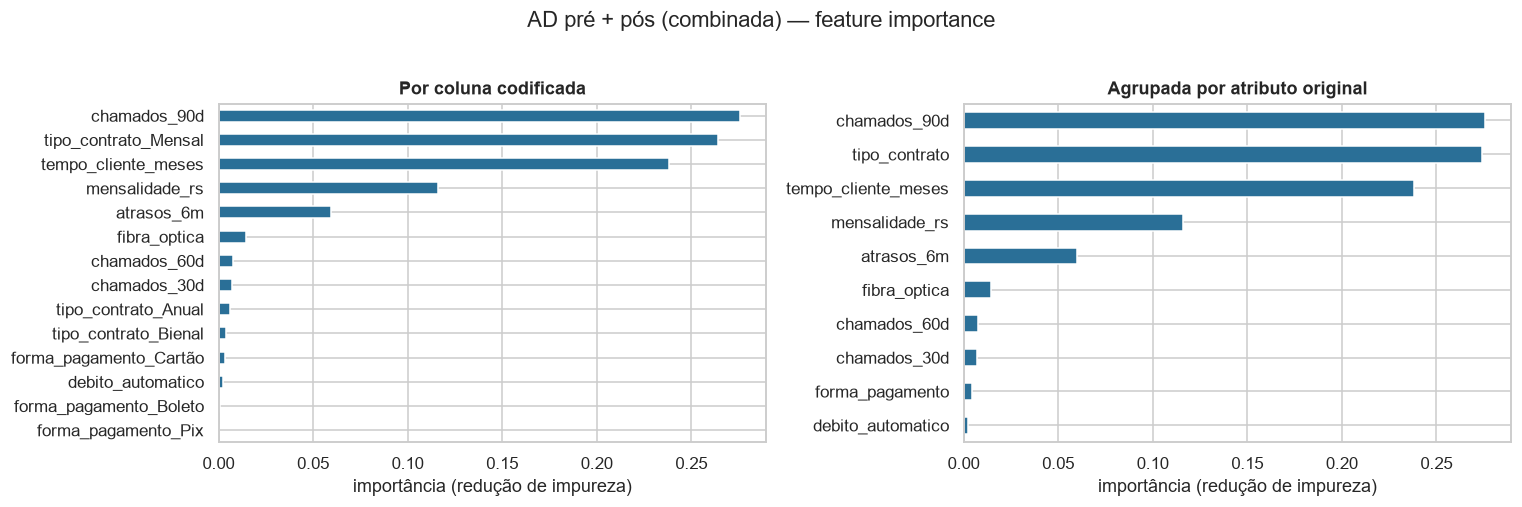

In [16]:
def agrupar(nome):
    for base in ("tipo_contrato", "forma_pagamento"):
        if nome.startswith(base + "_"):
            return base
    return nome

imp_ad = pd.Series(arvore.feature_importances_, index=nomes)
imp_ad_grp = imp_ad.groupby(agrupar).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
imp_ad.sort_values().plot.barh(ax=axes[0], color=COR["ad"]); axes[0].set_title("Por coluna codificada")
imp_ad_grp.plot.barh(ax=axes[1], color=COR["ad"]); axes[1].set_title("Agrupada por atributo original")
for ax in axes: ax.set_xlabel("importância (redução de impureza)")
plt.suptitle(f"{AD_FINAL_NOME} — feature importance", y=1.02); plt.tight_layout(); salvar("ad_importancia"); plt.show()

## 6. Módulo 2 — XGBoost

**Motivação (aula de Gradient Boosting — dilema viés-variância):** uma árvore rasa tem **alto viés** (não captura a
estrutura: *underfitting*); uma árvore profunda tem **alta variância** (memoriza ruído: *overfitting*), como vimos em
5.1. Os *ensembles* atacam o dilema por caminhos diferentes:

* **Bagging / Random Forest** (aula de Árvores): árvores profundas e descorrelacionadas (bootstrap + subconjunto
  aleatório de atributos), cuja média **reduz a variância**.
* **Boosting / XGBoost**: árvores rasas (*weak learners*) adicionadas em sequência, cada uma ajustando o gradiente
  do erro das anteriores — **reduz o viés** passo a passo; `learning_rate`, subamostragem e regularização controlam a
  variância.

### 6.1 Folds pré-processados e auditoria de equivalência

Para acelerar o Optuna e as curvas de aprendizado, pré-calculamos os 5 folds: **em cada fold o pré-processamento é
ajustado apenas na parte de treino do fold** e aplicado na parte de validação — exatamente o que o `Pipeline` faz.
A célula abaixo prova a equivalência comparando os scores com `cross_validate(Pipeline)`.

In [17]:
FOLDS = []
for tr, va in CV.split(X_train, y_train):
    prep = build_ml_preprocessor(numeric_imputation="knn").set_output(transform="pandas")
    Xa = prep.fit_transform(X_train.iloc[tr], y_train.iloc[tr])
    Xb = prep.transform(X_train.iloc[va])
    FOLDS.append((Xa, y_train.iloc[tr].to_numpy(), Xb, y_train.iloc[va].to_numpy()))

def xgb_modelo(params=None, n_jobs=N_THREADS, **extra):
    base = dict(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                random_state=SEED, n_jobs=n_jobs)
    return XGBClassifier(**{**base, **(params or {}), **extra})

def cv_folds(params, **extra):
    out = {"recall": [], "precision": [], "f2": [], "roc_auc": [], "pr_auc": [], "treino_recall": [], "treino_roc_auc": [], "treino_pr_auc": []}
    for Xa, ya, Xb, yb in FOLDS:
        m = xgb_modelo(params, **extra).fit(Xa, ya)
        pb, pa = m.predict_proba(Xb)[:, 1], m.predict_proba(Xa)[:, 1]
        out["recall"].append(recall_score(yb, pb >= .5)); out["precision"].append(precision_score(yb, pb >= .5))
        out["f2"].append(fbeta_score(yb, pb >= .5, beta=2)); out["roc_auc"].append(roc_auc_score(yb, pb))
        out["pr_auc"].append(average_precision_score(yb, pb)); out["treino_pr_auc"].append(average_precision_score(ya, pa))
        out["treino_recall"].append(recall_score(ya, pa >= .5)); out["treino_roc_auc"].append(roc_auc_score(ya, pa))
    return {k: float(np.mean(v)) for k, v in out.items()}

auditoria = cv_folds({})
via_pipeline = next(r for r in RESULTADOS_CV if r["modelo"] == "XGB padrão")
print(f"F2 folds pré-calculados: {auditoria['f2']:.6f} | via Pipeline: {via_pipeline['val_f2']:.6f}")
assert abs(auditoria["f2"] - via_pipeline["val_f2"]) < 1e-3, "folds pré-calculados divergem do Pipeline"
print("OK: os folds pré-calculados reproduzem exatamente o Pipeline (sem vazamento).")

F2 folds pré-calculados: 0.535178 | via Pipeline: 0.535178
OK: os folds pré-calculados reproduzem exatamente o Pipeline (sem vazamento).


### 6.2 Trade-off `learning_rate` × `n_estimators`

No boosting, cada árvore corrige os resíduos das anteriores com passo `learning_rate` (η). η pequeno exige mais
árvores, mas costuma generalizar melhor; η grande converge rápido e começa a sobreajustar cedo. Treinamos até 2.000
árvores (profundidade 3) para 5 taxas e acompanhamos a *log-loss* de validação a cada iteração.

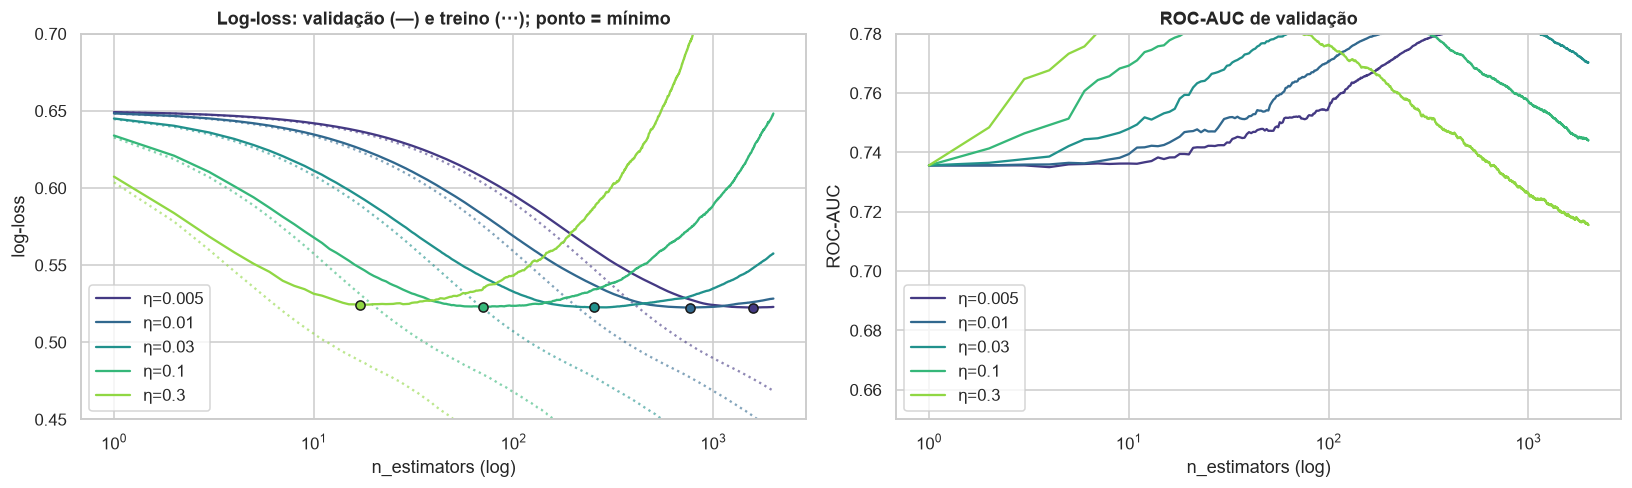

,learning_rate,melhor_n_estimators,logloss_val_min,auc_val_no_melhor,logloss_val_em_2000,logloss_treino_em_2000
0,0.005,1581,0.5226,0.7900,0.5230,0.4686
1,0.010,761,0.5225,0.7900,0.5284,0.4421
2,0.030,252,0.5226,0.7899,0.5576,0.3729
3,0.100,70,0.5231,0.7897,0.6483,0.2501
4,0.300,17,0.5243,0.7881,0.9062,0.1051


In [18]:
taxas = [0.005, 0.01, 0.03, 0.1, 0.3]
N_MAX = 2000
curvas = {}
for lr in taxas:
    tr_hist, va_hist, auc_hist = [], [], []
    for Xa, ya, Xb, yb in FOLDS:
        m = xgb_modelo({"learning_rate": lr, "n_estimators": N_MAX, "max_depth": 3},
                       eval_metric=["logloss", "auc"]).fit(Xa, ya, eval_set=[(Xa, ya), (Xb, yb)], verbose=False)
        ev = m.evals_result()
        tr_hist.append(ev["validation_0"]["logloss"]); va_hist.append(ev["validation_1"]["logloss"])
        auc_hist.append(ev["validation_1"]["auc"])
    curvas[lr] = {"treino": np.mean(tr_hist, 0), "val": np.mean(va_hist, 0), "auc": np.mean(auc_hist, 0)}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
pal = sns.color_palette("viridis", len(taxas))
tab = []
for cor, lr in zip(pal, taxas):
    c = curvas[lr]; it = np.arange(1, N_MAX + 1); best = int(c["val"].argmin())
    axes[0].plot(it, c["val"], color=cor, label=f"η={lr}"); axes[0].plot(it, c["treino"], color=cor, ls=":", alpha=.6)
    axes[0].scatter(best + 1, c["val"][best], color=cor, edgecolor="k", zorder=5)
    axes[1].plot(it, c["auc"], color=cor, label=f"η={lr}")
    tab.append({"learning_rate": lr, "melhor_n_estimators": best + 1, "logloss_val_min": c["val"][best],
                "auc_val_no_melhor": c["auc"][best], "logloss_val_em_2000": c["val"][-1],
                "logloss_treino_em_2000": c["treino"][-1]})
axes[0].set(xscale="log", ylim=(0.45, 0.70), xlabel="n_estimators (log)", ylabel="log-loss",
            title="Log-loss: validação (—) e treino (···); ponto = mínimo")
axes[1].set(xscale="log", ylim=(0.65, 0.78), xlabel="n_estimators (log)", ylabel="ROC-AUC", title="ROC-AUC de validação")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); salvar("xgb_tradeoff_lr_n_estimators"); plt.show()
tradeoff = pd.DataFrame(tab).round(4); tradeoff

**Leitura:** o produto η × n_estimators é aproximadamente constante no ponto ótimo (η menor → mínimo mais à direita).
Para η ≥ 0,1 a log-loss de validação sobe logo depois do mínimo enquanto a de treino continua caindo — sobreajuste.
Esse resultado orientou os espaços de busca abaixo: η entre ~0,005 e 0,3 e `n_estimators` entre 100 e 1.000.

### 6.3 GridSearchCV (busca exaustiva)

Grade compacta e justificada (192 combinações × 5 folds), usando o mesmo `Pipeline` com pré-processamento por fold:

| Hiperparâmetro | Valores | Racional |
|---|---|---|
| `n_estimators` × `learning_rate` | {200, 500} × {0,03; 0,1} | região próxima aos ótimos da Seção 6.2 |
| `max_depth` | 2, 3, 4 | árvores rasas (weak learners); 6+ sobreajustou nas curvas |
| `subsample`, `colsample_bytree` | {0,7; 1,0} | amostragem estocástica de linhas/colunas reduz variância |
| `min_child_weight` | 1, 5 | exige massa mínima de hessiano por folha |
| `scale_pos_weight` | 1; ≈1,82 (neg/pos) | ponderação da classe churn (além da lista do enunciado) |

`gamma`, `reg_alpha` e `reg_lambda` ficam no padrão aqui e são explorados de forma contínua no Optuna (6.4) — uma
grade com eles multiplicaria o custo por 27.

In [19]:
grade_xgb = {
    "model__n_estimators": [200, 500],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.7, 1.0],
    "model__colsample_bytree": [0.7, 1.0],
    "model__min_child_weight": [1, 5],
    "model__scale_pos_weight": [1.0, round(SPW, 3)],
}
pipe_xgb = make_pipeline(xgb_modelo(n_jobs=1), memory=CACHE)
t0 = time.time()
gs_xgb = GridSearchCV(pipe_xgb, grade_xgb, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=N_JOBS,
                      return_train_score=True).fit(X_train, y_train)
t_grid = time.time() - t0
XGB_GRID = gs_xgb.best_estimator_
params_grid = {k.replace("model__", ""): v for k, v in gs_xgb.best_params_.items()}
print(f"GridSearch: {len(gs_xgb.cv_results_['params'])} combinações em {t_grid:.0f}s → PR-AUC val {gs_xgb.best_score_:.4f}")
print("Melhores:", params_grid)
top(gs_xgb)

GridSearch: 192 combinações em 110s → PR-AUC val 0.6706
Melhores: {'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 500, 'scale_pos_weight': 1.0, 'subsample': 1.0}


,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,scale_pos_weight,subsample,test_pr_auc,std_test_pr_auc,test_roc_auc,test_recall,test_precision,train_pr_auc,train_roc_auc
0,1.0,0.03,2,1,500,1.000,1.0,0.671,0.027,0.792,0.527,0.662,0.717,0.823
1,1.0,0.03,2,1,500,1.823,1.0,0.670,0.028,0.792,0.730,0.573,0.716,0.824
2,1.0,0.03,2,5,500,1.000,1.0,0.670,0.029,0.792,0.528,0.665,0.712,0.822
3,0.7,0.03,3,1,200,1.823,1.0,0.669,0.026,0.791,0.736,0.575,0.717,0.827
4,1.0,0.03,2,5,500,1.823,0.7,0.669,0.028,0.792,0.730,0.575,0.714,0.825
5,1.0,0.03,2,5,500,1.823,1.0,0.669,0.029,0.792,0.732,0.574,0.711,0.823
6,1.0,0.03,2,1,500,1.823,0.7,0.669,0.027,0.792,0.731,0.581,0.719,0.826
7,1.0,0.03,2,5,500,1.000,0.7,0.669,0.027,0.791,0.532,0.662,0.717,0.825


### 6.4 Optuna (otimização bayesiana com TPE + poda de tentativas)

* **Amostrador TPE** (Tree-structured Parzen Estimator): modela regiões promissoras e amostra preferencialmente nelas.
* **Objetivo:** PR-AUC média nos 5 folds (mesmo critério do GridSearch).
* **MedianPruner**: após cada fold, se a PR-AUC parcial da tentativa estiver abaixo da mediana das tentativas anteriores no
  mesmo fold, ela é interrompida — economiza tempo em configurações ruins.
* Espaço **contínuo** (escala log onde a ordem de grandeza importa), com 10 hiperparâmetros, incluindo `gamma`,
  `reg_alpha`, `reg_lambda`, `min_child_weight` e `scale_pos_weight`.

In [20]:
def objetivo(trial):
    p = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 30, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "gamma": trial.suggest_float("gamma", 1e-3, 5.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 3.0),
    }
    aps, recs, precs, aucs = [], [], [], []
    for k, (Xa, ya, Xb, yb) in enumerate(FOLDS):
        proba = xgb_modelo(p).fit(Xa, ya).predict_proba(Xb)[:, 1]
        aps.append(average_precision_score(yb, proba)); recs.append(recall_score(yb, proba >= .5))
        precs.append(precision_score(yb, proba >= .5)); aucs.append(roc_auc_score(yb, proba))
        trial.report(float(np.mean(aps)), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("recall", float(np.mean(recs))); trial.set_user_attr("precision", float(np.mean(precs)))
    trial.set_user_attr("roc_auc", float(np.mean(aucs)))
    return float(np.mean(aps))

estudo = optuna.create_study(direction="maximize", study_name="xgb_churn_pr_auc",
                             sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=15),
                             pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1))
t0 = time.time()
estudo.optimize(objetivo, n_trials=120, timeout=900)
t_optuna = time.time() - t0
estados = pd.Series([t.state.name for t in estudo.trials]).value_counts()
params_optuna = estudo.best_params
print(f"Optuna: {len(estudo.trials)} tentativas em {t_optuna:.0f}s ({estados.to_dict()})")
print(f"Melhor PR-AUC val {estudo.best_value:.4f} | recall@0,5 {estudo.best_trial.user_attrs['recall']:.3f} | "
      f"precisão {estudo.best_trial.user_attrs['precision']:.3f} | AUC {estudo.best_trial.user_attrs['roc_auc']:.3f}")
print("Melhores:", {k: round(v, 4) if isinstance(v, float) else v for k, v in params_optuna.items()})
estudo.trials_dataframe().to_csv(REPORTS / "optuna_trials.csv", index=False)

Optuna: 120 tentativas em 170s ({'COMPLETE': 119, 'PRUNED': 1})
Melhor PR-AUC val 0.6700 | recall@0,5 0.707 | precisão 0.586 | AUC 0.793
Melhores: {'n_estimators': 850, 'learning_rate': 0.0106, 'max_depth': 2, 'min_child_weight': 10.8471, 'subsample': 0.8509, 'colsample_bytree': 0.9369, 'gamma': 0.0456, 'reg_alpha': 0.0051, 'reg_lambda': 0.0069, 'scale_pos_weight': 1.6883}


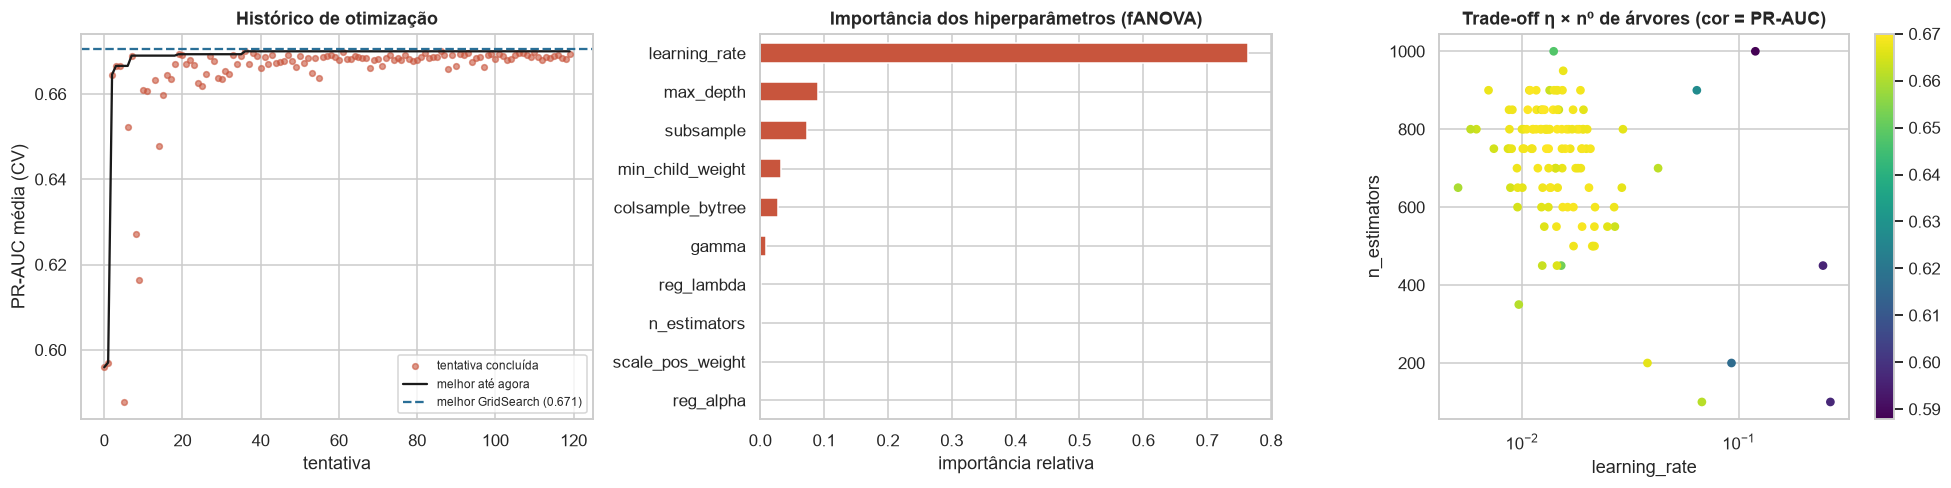

In [21]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
ok = [t for t in estudo.trials if t.state.name == "COMPLETE"]
vals = [t.value for t in ok]
axes[0].scatter([t.number for t in ok], vals, s=14, color=COR["xgb"], alpha=.6, label="tentativa concluída")
axes[0].plot([t.number for t in ok], np.maximum.accumulate(vals), color="k", label="melhor até agora")
axes[0].axhline(gs_xgb.best_score_, ls="--", color=COR["ad"], label=f"melhor GridSearch ({gs_xgb.best_score_:.3f})")
axes[0].set(xlabel="tentativa", ylabel="PR-AUC média (CV)", title="Histórico de otimização"); axes[0].legend(fontsize=8)

imp_par = optuna.importance.get_param_importances(estudo, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
pd.Series(imp_par).sort_values().plot.barh(ax=axes[1], color=COR["xgb"])
axes[1].set(title="Importância dos hiperparâmetros (fANOVA)", xlabel="importância relativa")

sc = axes[2].scatter([t.params["learning_rate"] for t in ok], [t.params["n_estimators"] for t in ok],
                     c=vals, cmap="viridis", s=22)
axes[2].set(xscale="log", xlabel="learning_rate", ylabel="n_estimators", title="Trade-off η × nº de árvores (cor = PR-AUC)")
plt.colorbar(sc, ax=axes[2])
plt.tight_layout(); salvar("xgb_optuna"); plt.show()

### 6.5 GridSearchCV × Optuna

In [22]:
XGB_OPTUNA = make_pipeline(xgb_modelo(params_optuna, n_jobs=1), memory=CACHE).fit(X_train, y_train)
RESULTADOS_CV.append(cv_resumo("XGB GridSearch", XGB_GRID))
RESULTADOS_CV.append(cv_resumo("XGB Optuna", XGB_OPTUNA))
buscas = pd.DataFrame({
    "configurações avaliadas": [len(gs_xgb.cv_results_["params"]), len(estudo.trials)],
    "concluídas (5 folds)": [len(gs_xgb.cv_results_["params"]), int(estados.get("COMPLETE", 0))],
    "podadas": [0, int(estados.get("PRUNED", 0))],
    "hiperparâmetros": [len(grade_xgb), len(params_optuna)],
    "tempo (s)": [t_grid, t_optuna],
    "melhor PR-AUC val": [gs_xgb.best_score_, estudo.best_value],
}, index=["GridSearchCV", "Optuna (TPE)"]).round(4)
display(buscas)
mostrar([r for r in RESULTADOS_CV if r["modelo"].startswith("XGB")])

,configurações avaliadas,concluídas (5 folds),podadas,hiperparâmetros,tempo (s),melhor PR-AUC val
GridSearchCV,192,192,0,7,109.6775,0.6706
Optuna (TPE),120,119,1,10,169.8058,0.6700


,val_recall,val_precision,val_f1,val_f2,val_roc_auc,val_pr_auc,treino_recall,treino_roc_auc,gap_recall,gap_auc
modelo,,,,,,,,,,
XGB padrão,0.524,0.585,0.553,0.535,0.747,0.609,0.929,0.996,0.405,0.249
XGB GridSearch,0.527,0.662,0.586,0.549,0.792,0.671,0.550,0.823,0.023,0.031
XGB Optuna,0.706,0.586,0.640,0.678,0.792,0.668,0.730,0.816,0.024,0.024


### 6.6 Hipótese: restrições monotônicas tornam o XGBoost mais confiável sem perder desempenho?

A EDA e o próprio treino mostram relações monotônicas claras: mais atrasos e mais chamados → mais churn;
mais tempo de casa → menos churn; mensalidade maior → mais churn. Forçar essas direções (`monotone_constraints`)
impede que o modelo aprenda "dentes" espúrios em regiões com poucos clientes (ex.: 5 atrasos com só 4 clientes) e
torna as explicações coerentes para o negócio.

Regra definida *a priori*: adotamos a versão restrita se a perda de PR-AUC de validação for **menor que 0,005**.

In [23]:
monotonia = {"numeric__atrasos_6m": 1, "numeric__chamados_30d": 1, "numeric__chamados_60d": 1,
             "numeric__chamados_90d": 1, "numeric__tempo_cliente_meses": -1, "numeric__mensalidade_rs": 1}
t = Xtr_t.assign(churn=y_train.values)
print("Taxa de churn no treino por nível (evidência para as restrições):")
for c in ["atrasos_6m", "chamados_90d"]:
    print(c, t.groupby(t[f"numeric__{c}"].clip(upper=6))["churn"].mean().round(2).to_dict())

livre = cv_folds(params_optuna)
restrito = cv_folds(params_optuna, monotone_constraints=monotonia)
mono_tab = pd.DataFrame({"XGB Optuna (livre)": livre, "XGB Optuna + monotônico": restrito}).T.round(4)
display(mono_tab)
XGB_MONO = make_pipeline(xgb_modelo(params_optuna, n_jobs=1, monotone_constraints=monotonia), memory=CACHE).fit(X_train, y_train)
RESULTADOS_CV.append(cv_resumo("XGB Optuna + monotônico", XGB_MONO))
usar_mono = restrito["pr_auc"] > livre["pr_auc"] - 0.005
XGB_FINAL_NOME = "XGB Optuna + monotônico" if usar_mono else "XGB Optuna"
XGB_FINAL = XGB_MONO if usar_mono else XGB_OPTUNA
print(f"XGBoost escolhido: {XGB_FINAL_NOME} (ΔPR-AUC = {restrito['pr_auc'] - livre['pr_auc']:+.4f}; "
      f"Δgap AUC = {(restrito['treino_roc_auc']-restrito['roc_auc']) - (livre['treino_roc_auc']-livre['roc_auc']):+.4f})")

Taxa de churn no treino por nível (evidência para as restrições):
atrasos_6m {0.0: 0.24, 1.0: 0.35, 2.0: 0.46, 3.0: 0.57, 4.0: 0.78, 5.0: 0.25}
chamados_90d {0.0: 0.2, 1.0: 0.27, 2.0: 0.38, 3.0: 0.49, 4.0: 0.56, 5.0: 0.65, 6.0: 0.74}


,recall,precision,f2,roc_auc,pr_auc,treino_recall,treino_roc_auc,treino_pr_auc
XGB Optuna (livre),0.7074,0.5862,0.6792,0.7926,0.6700,0.7303,0.8162,0.6993
XGB Optuna + monotônico,0.7091,0.5854,0.6801,0.7932,0.6715,0.7281,0.8130,0.6947


XGBoost escolhido: XGB Optuna + monotônico (ΔPR-AUC = +0.0015; Δgap AUC = -0.0038)


### 6.6b Comparação da aula: Random Forest (bagging) × XGBoost (boosting)

Random Forest com grade compacta: `max_features` = √p (padrão da aula) ou 50% dos atributos, profundidade e
tamanho mínimo de folha, `class_weight` balanceado por amostra bootstrap. Mesma CV, mesmo critério (PR-AUC).

In [24]:
from sklearn.ensemble import RandomForestClassifier
grade_rf = {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 10, 30],
            "model__max_features": ["sqrt", 0.5], "model__class_weight": [None, "balanced_subsample"]}
pipe_rf = make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1), memory=CACHE)
t0 = time.time()
gs_rf = GridSearchCV(pipe_rf, grade_rf, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=N_JOBS,
                     return_train_score=True).fit(X_train, y_train)
t_rf = time.time() - t0
RF_BEST = gs_rf.best_estimator_
params_rf = {k.replace("model__", ""): v for k, v in gs_rf.best_params_.items()}
RESULTADOS_CV.append(cv_resumo("Random Forest", RF_BEST))
print(f"Random Forest ({t_rf:.0f}s, {len(gs_rf.cv_results_['params'])} combinações): {params_rf} → PR-AUC val {gs_rf.best_score_:.4f}")
mostrar([r for r in RESULTADOS_CV if r["modelo"] in ("AD sem poda", AD_FINAL_NOME, "Random Forest", "XGB GridSearch", "XGB Optuna", "XGB Optuna + monotônico")])

Random Forest (80s, 48 combinações): {'class_weight': None, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1} → PR-AUC val 0.6657


,val_recall,val_precision,val_f1,val_f2,val_roc_auc,val_pr_auc,treino_recall,treino_roc_auc,gap_recall,gap_auc
modelo,,,,,,,,,,
AD sem poda,0.491,0.489,0.490,0.491,0.604,0.421,1.000,1.000,0.509,0.396
AD pré + pós (combinada),0.474,0.611,0.533,0.496,0.748,0.609,0.533,0.809,0.059,0.061
XGB GridSearch,0.527,0.662,0.586,0.549,0.792,0.671,0.550,0.823,0.023,0.031
XGB Optuna,0.706,0.586,0.640,0.678,0.792,0.668,0.730,0.816,0.024,0.024
XGB Optuna + monotônico,0.707,0.583,0.639,0.678,0.793,0.670,0.727,0.813,0.020,0.020
Random Forest,0.502,0.665,0.571,0.527,0.783,0.666,0.637,0.903,0.136,0.120


### 6.7 Importância de atributos no XGBoost

`gain` = ganho médio de qualidade das divisões que usam o atributo; `weight` = quantas vezes ele é usado. Os dois
contam histórias diferentes: atributos contínuos tendem a ter muitas divisões (weight alto) com ganho pequeno.

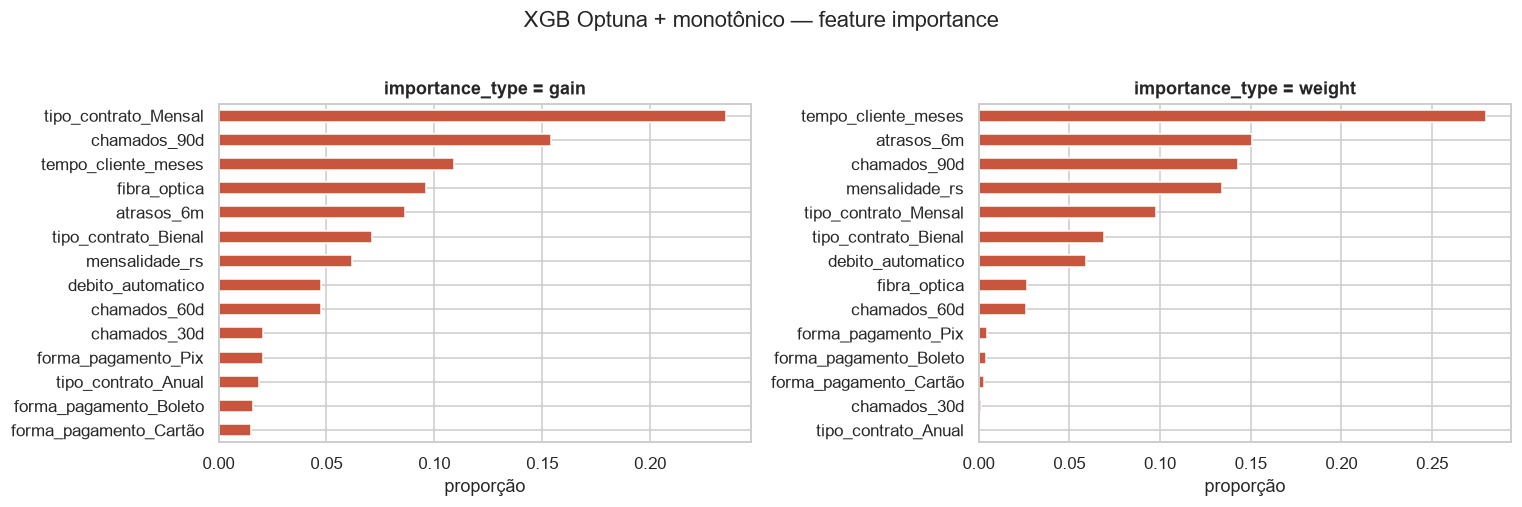

In [25]:
booster = XGB_FINAL[-1].get_booster()
imp_xgb = pd.DataFrame({tipo: pd.Series(booster.get_score(importance_type=tipo)) for tipo in ["gain", "weight"]}).fillna(0)
imp_xgb.index = [clean_name(i) for i in imp_xgb.index]
imp_xgb = imp_xgb / imp_xgb.sum()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, tipo in zip(axes, ["gain", "weight"]):
    imp_xgb[tipo].sort_values().plot.barh(ax=ax, color=COR["xgb"]); ax.set(title=f"importance_type = {tipo}", xlabel="proporção")
plt.suptitle(f"{XGB_FINAL_NOME} — feature importance", y=1.02); plt.tight_layout(); salvar("xgb_importancia"); plt.show()

## 7. Hipóteses autônomas da equipe

Todas avaliadas por CV 5-fold no treino, com os melhores hiperparâmetros de cada família e tudo dentro do `Pipeline`.

* **H1 — Imputação:** o KNN escolhido no miniprojeto 1 (melhor reconstrução de valores mascarados) também melhora a
  **predição** em relação à mediana? Reconstruir bem um valor não garante prever melhor o churn.
* **H2 — Engenharia de atributos:** atributos derivados (aceleração de chamados nos últimos 30 dias, chamados entre 61–90
  dias, valor acumulado = mensalidade × permanência, indicador de atraso) ajudam árvores, que só fazem cortes
  ortogonais e têm dificuldade com razões/produtos?
* **H3 — Ponderação de classe × limiar:** `class_weight`/`scale_pos_weight` e mover o limiar de decisão são formas
  alternativas de trocar precisão por recall. Testada na Seção 8.
* **H4 — Boosting compensa?** O ganho do XGBoost sobre uma árvore podada é estatisticamente distinguível? Testada na
  Seção 9 com bootstrap pareado.
* **H5 — Restrições monotônicas:** já testada em 6.6.

In [26]:
from sklearn.base import clone
ad_params = {k: v for k, v in AD_FINAL[-1].get_params().items()}
xgb_final_model = XGB_FINAL[-1]
hip = []
for imp in ["knn", "median"]:
    for eng in [False, True]:
        rot = f"imputação={imp} | eng={'sim' if eng else 'não'}"
        r_ad = cv_resumo(f"AD — {rot}", make_pipeline(DecisionTreeClassifier(**ad_params), numeric_imputation=imp, engineered=eng, memory=CACHE))
        xgb_p = {k: v for k, v in xgb_final_model.get_params().items() if k != "monotone_constraints"}
        r_xgb = cv_resumo(f"XGB — {rot}", make_pipeline(XGBClassifier(**{**xgb_p, "n_jobs": 1}), numeric_imputation=imp, engineered=eng, memory=CACHE))
        hip += [r_ad, r_xgb]
hip_tab = pd.DataFrame(hip).set_index("modelo")[["val_pr_auc", "val_pr_auc_std", "val_roc_auc", "val_recall", "val_precision", "gap_auc"]].round(4)
display(hip_tab)

,val_pr_auc,val_pr_auc_std,val_roc_auc,val_recall,val_precision,gap_auc
modelo,,,,,,
AD — imputação=knn | eng=não,0.6087,0.0165,0.7478,0.4741,0.6111,0.0615
XGB — imputação=knn | eng=não,0.6683,0.0268,0.7920,0.7058,0.5865,0.0242
AD — imputação=knn | eng=sim,0.6071,0.0228,0.7493,0.4741,0.6165,0.0620
XGB — imputação=knn | eng=sim,0.6693,0.0285,0.7926,0.7066,0.5881,0.0266
AD — imputação=median | eng=não,0.6046,0.0166,0.7541,0.5146,0.6109,0.0543
XGB — imputação=median | eng=não,0.6668,0.0270,0.7922,0.7050,0.5849,0.0244
AD — imputação=median | eng=sim,0.6077,0.0256,0.7553,0.4951,0.6209,0.0554
XGB — imputação=median | eng=sim,0.6697,0.0278,0.7928,0.7042,0.5857,0.0266


**Como ler:** diferenças de PR-AUC menores que o desvio-padrão entre folds (`val_pr_auc_std`) não são evidência de
melhoria real. Mantemos a configuração do miniprojeto 1 (KNN, sem atributos derivados) a menos que uma alternativa
supere essa margem — evitando "otimizar ruído" da validação.

## 8. Escolha do limiar de decisão (recall × precisão × custo)

Como visto em aula, a árvore (e o XGBoost) produzem uma probabilidade contínua via `predict_proba`, e a classe sai
de um limiar — por padrão 0,5, que não tem nada de especial. Como o recall é prioritário, escolhemos o limiar com **probabilidades
out-of-fold do treino** (`cross_val_predict`), **sem tocar no teste**:

1. **Meta de recall ≥ 80%**: o maior limiar que ainda recupera 80% dos churners na validação.
2. **Custo mínimo** (hipótese ilustrativa, ajustável pelo negócio): perder um cliente (FN) custa **5×** mais que uma
   oferta de retenção desnecessária (FP).

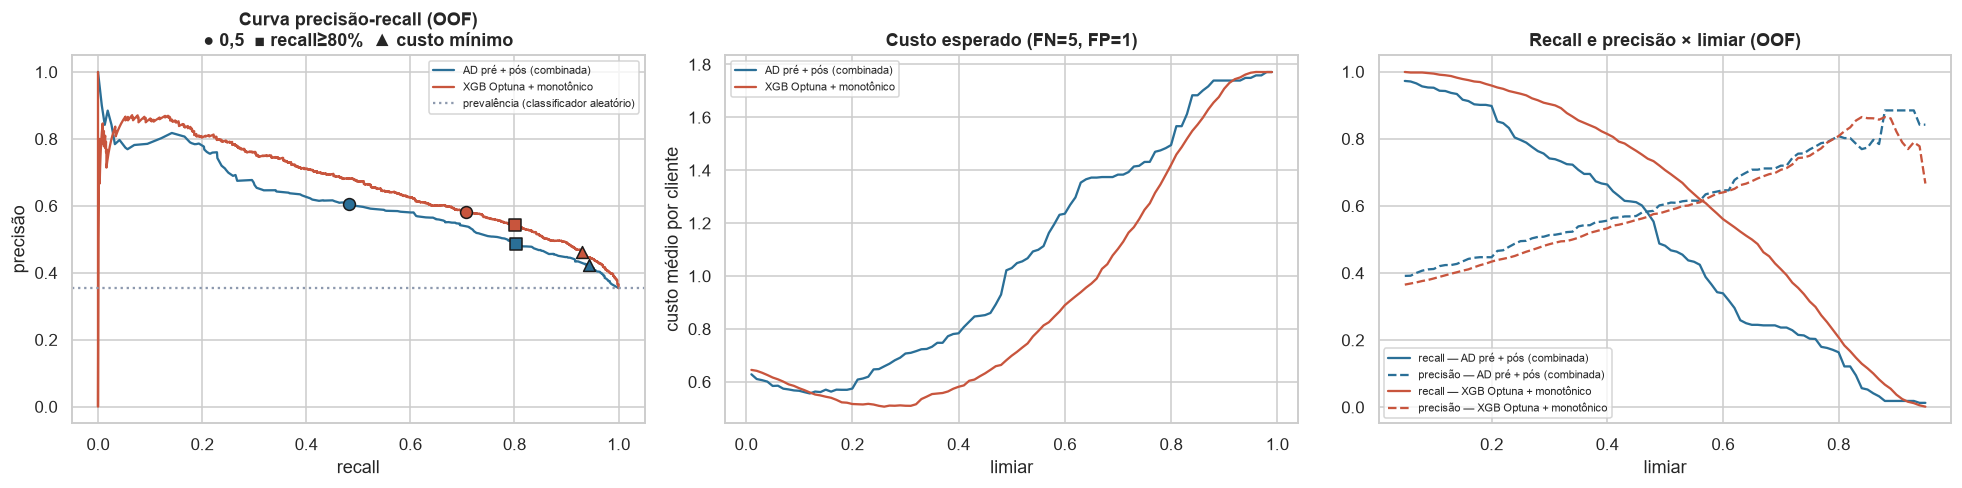

,modelo,critério,limiar,recall,precision,f2
0,AD pré + pós (combinada),"padrão 0,5",0.500,0.481,0.605,0.502
1,AD pré + pós (combinada),recall ≥ 80%,0.243,0.804,0.487,0.711
2,AD pré + pós (combinada),custo mínimo (FN=5·FP),0.120,0.942,0.424,0.757
3,XGB Optuna + monotônico,"padrão 0,5",0.500,0.707,0.583,0.678
4,XGB Optuna + monotônico,recall ≥ 80%,0.412,0.801,0.541,0.731
5,XGB Optuna + monotônico,custo mínimo (FN=5·FP),0.260,0.929,0.463,0.774


In [27]:
META_RECALL = 0.80
C_FN, C_FP = 5.0, 1.0
FINAIS = {AD_FINAL_NOME: AD_FINAL, XGB_FINAL_NOME: XGB_FINAL}
OOF, LIMIARES = {}, {}
for nome, modelo in FINAIS.items():
    OOF[nome] = cross_val_predict(modelo, X_train, y_train, cv=CV, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    t_rec = threshold_for_recall(y_train, OOF[nome], META_RECALL)
    t_cost, grade_t, custos = threshold_min_cost(y_train.to_numpy(), OOF[nome], C_FN, C_FP)
    LIMIARES[nome] = {"padrão 0,5": 0.5, f"recall ≥ {META_RECALL:.0%}": t_rec, "custo mínimo (FN=5·FP)": t_cost,
                      "_custos": (grade_t, custos)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for (nome, proba), cor in zip(OOF.items(), [COR["ad"], COR["xgb"]]):
    p, r, t = precision_recall_curve(y_train, proba)
    axes[0].plot(r, p, color=cor, label=nome)
    for (rot, thr), mk in zip([(k, v) for k, v in LIMIARES[nome].items() if not k.startswith("_")], ["o", "s", "^"]):
        m = metrics_at(y_train, proba, thr)
        axes[0].scatter(m["recall"], m["precision"], color=cor, marker=mk, s=60, edgecolor="k", zorder=5)
    grade_t, custos = LIMIARES[nome]["_custos"]
    axes[1].plot(grade_t, custos / len(y_train), color=cor, label=nome)
    ts = np.linspace(0.05, 0.95, 91)
    axes[2].plot(ts, [recall_score(y_train, proba >= x) for x in ts], color=cor, label=f"recall — {nome}")
    axes[2].plot(ts, [precision_score(y_train, proba >= x, zero_division=0) for x in ts], color=cor, ls="--", label=f"precisão — {nome}")
axes[0].axhline(y_train.mean(), color=COR["base"], ls=":", label="prevalência (classificador aleatório)")
axes[0].set(xlabel="recall", ylabel="precisão", title="Curva precisão-recall (OOF)\n● 0,5  ■ recall≥80%  ▲ custo mínimo")
axes[1].set(xlabel="limiar", ylabel="custo médio por cliente", title=f"Custo esperado (FN={C_FN:.0f}, FP={C_FP:.0f})")
axes[2].set(xlabel="limiar", title="Recall e precisão × limiar (OOF)")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); salvar("limiar_trade_off"); plt.show()

lim_tab = pd.DataFrame([{"modelo": n, "critério": k, "limiar": v, **{m: metrics_at(y_train, OOF[n], v)[m] for m in ["recall", "precision", "f2"]}}
                        for n in FINAIS for k, v in LIMIARES[n].items() if not k.startswith("_")]).round(3)
lim_tab

## 9. Avaliação final no teste (30% — avaliação cega)

Todos os modelos foram reajustados no treino completo pelo `refit` das buscas; o teste é usado **uma única vez**
aqui. Primeiro com limiar 0,5; depois com os limiares escolhidos na Seção 8.

In [28]:
AD_SEM_PODA = make_pipeline(DecisionTreeClassifier(random_state=SEED)).fit(X_train, y_train)
XGB_PADRAO = make_pipeline(xgb_modelo()).fit(X_train, y_train)
DUMMY = make_pipeline(DummyClassifier(strategy="stratified", random_state=SEED)).fit(X_train, y_train)
MODELOS = {"Dummy (estratificado)": DUMMY, "AD sem poda": AD_SEM_PODA, "AD pré-poda": AD_PRE,
           "AD pós-poda (ccp_alpha)": AD_POS, "XGB padrão": XGB_PADRAO, "XGB GridSearch": XGB_GRID,
           "XGB Optuna": XGB_OPTUNA, "XGB Optuna + monotônico": XGB_MONO, "Random Forest": RF_BEST,
           "AD pré + pós (combinada)": AD_COMB}
PROBA_TESTE = {n: m.predict_proba(X_test)[:, 1] for n, m in MODELOS.items()}
PROBA_TREINO = {n: m.predict_proba(X_train)[:, 1] for n, m in MODELOS.items()}

teste_05 = pd.DataFrame({n: metrics_at(y_test, p, 0.5) for n, p in PROBA_TESTE.items()}).T
cols_m = ["recall", "precision", "f1", "f2", "accuracy", "roc_auc", "pr_auc", "tp", "fp", "fn", "tn"]
print("Teste — limiar 0,5")
display(teste_05[cols_m].astype(float).round(3))

linhas = []
for n in FINAIS:
    for crit, thr in LIMIARES[n].items():
        if crit.startswith("_"): continue
        linhas.append({"modelo": n, "critério do limiar": crit, **metrics_at(y_test, PROBA_TESTE[n], thr)})
teste_thr = pd.DataFrame(linhas)
print("Teste — modelos finais com limiares escolhidos no treino (OOF)")
display(teste_thr[["modelo", "critério do limiar", "threshold"] + cols_m].round(3))
teste_05.to_csv(REPORTS / "metricas_teste_limiar_05.csv"); teste_thr.to_csv(REPORTS / "metricas_teste_limiares.csv", index=False)

Teste — limiar 0,5


,recall,precision,f1,f2,accuracy,roc_auc,pr_auc,tp,fp,fn,tn
Dummy (estratificado),0.384,0.382,0.383,0.383,0.561,0.521,0.365,203.0,329.0,326.0,635.0
AD sem poda,0.510,0.512,0.511,0.511,0.654,0.622,0.435,270.0,257.0,259.0,707.0
AD pré-poda,0.735,0.520,0.609,0.679,0.666,0.743,0.591,389.0,359.0,140.0,605.0
AD pós-poda (ccp_alpha),0.775,0.516,0.620,0.704,0.663,0.743,0.577,410.0,384.0,119.0,580.0
XGB padrão,0.541,0.627,0.581,0.556,0.723,0.772,0.631,286.0,170.0,243.0,794.0
XGB GridSearch,0.548,0.674,0.605,0.570,0.746,0.802,0.679,290.0,140.0,239.0,824.0
XGB Optuna,0.720,0.597,0.653,0.692,0.729,0.802,0.679,381.0,257.0,148.0,707.0
XGB Optuna + monotônico,0.718,0.597,0.652,0.690,0.728,0.802,0.678,380.0,257.0,149.0,707.0
Random Forest,0.514,0.678,0.585,0.540,0.741,0.796,0.667,272.0,129.0,257.0,835.0
AD pré + pós (combinada),0.544,0.625,0.582,0.559,0.723,0.751,0.604,288.0,173.0,241.0,791.0


Teste — modelos finais com limiares escolhidos no treino (OOF)


,modelo,critério do limiar,threshold,recall,precision,f1,f2,accuracy,roc_auc,pr_auc,tp,fp,fn,tn
0,AD pré + pós (combinada),"padrão 0,5",0.500,0.544,0.625,0.582,0.559,0.723,0.751,0.604,288,173,241,791
1,AD pré + pós (combinada),recall ≥ 80%,0.243,0.854,0.465,0.603,0.732,0.601,0.751,0.604,452,519,77,445
2,AD pré + pós (combinada),custo mínimo (FN=5·FP),0.120,0.922,0.440,0.595,0.756,0.556,0.751,0.604,488,622,41,342
3,XGB Optuna + monotônico,"padrão 0,5",0.500,0.718,0.597,0.652,0.690,0.728,0.802,0.678,380,257,149,707
4,XGB Optuna + monotônico,recall ≥ 80%,0.412,0.815,0.545,0.653,0.741,0.693,0.802,0.678,431,360,98,604
5,XGB Optuna + monotônico,custo mínimo (FN=5·FP),0.260,0.936,0.460,0.617,0.775,0.588,0.802,0.678,495,581,34,383


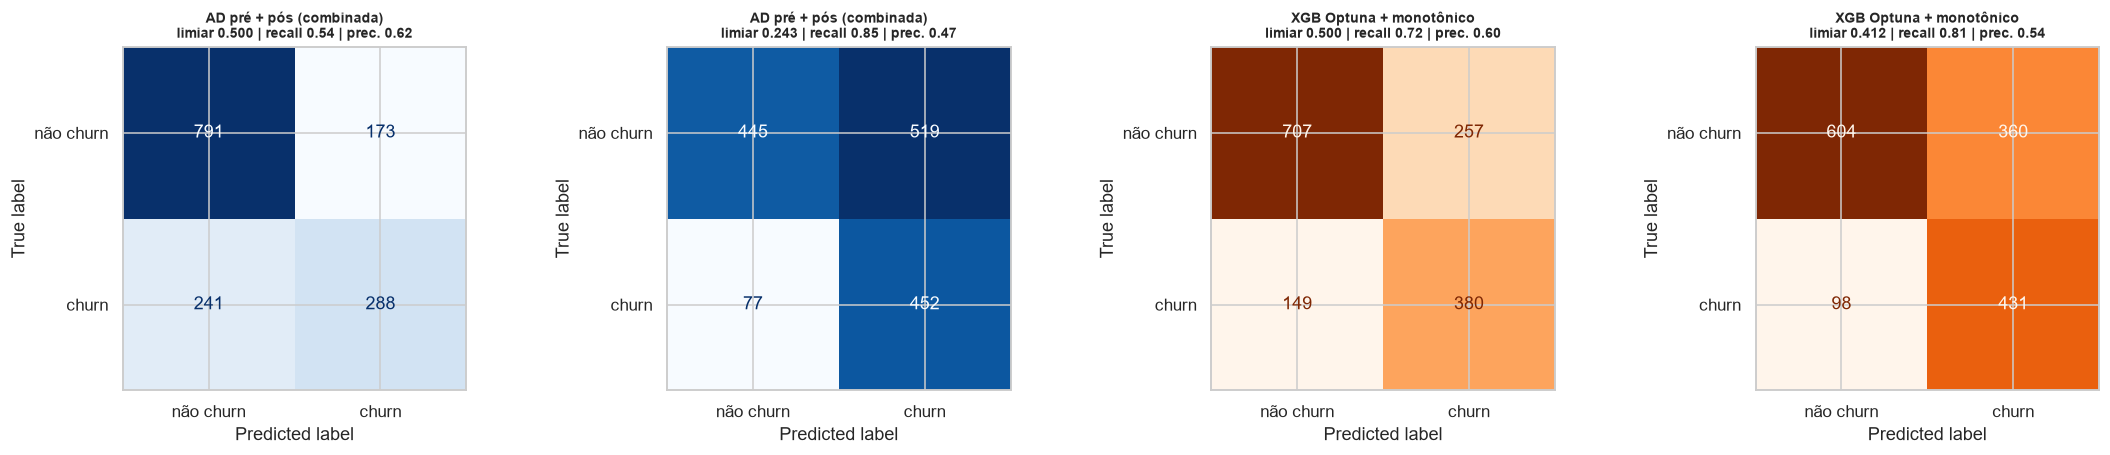

In [29]:
crit_rec = f"recall ≥ {META_RECALL:.0%}"
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
paineis = [(AD_FINAL_NOME, 0.5), (AD_FINAL_NOME, LIMIARES[AD_FINAL_NOME][crit_rec]),
           (XGB_FINAL_NOME, 0.5), (XGB_FINAL_NOME, LIMIARES[XGB_FINAL_NOME][crit_rec])]
for ax, (n, thr) in zip(axes, paineis):
    ConfusionMatrixDisplay.from_predictions(y_test, (PROBA_TESTE[n] >= thr).astype(int), display_labels=["não churn", "churn"],
                                            cmap="Blues" if n.startswith("AD") else "Oranges", colorbar=False, ax=ax)
    m = metrics_at(y_test, PROBA_TESTE[n], thr)
    ax.set_title(f"{n}\nlimiar {thr:.3f} | recall {m['recall']:.2f} | prec. {m['precision']:.2f}", fontsize=9)
plt.tight_layout(); salvar("matrizes_confusao_teste"); plt.show()

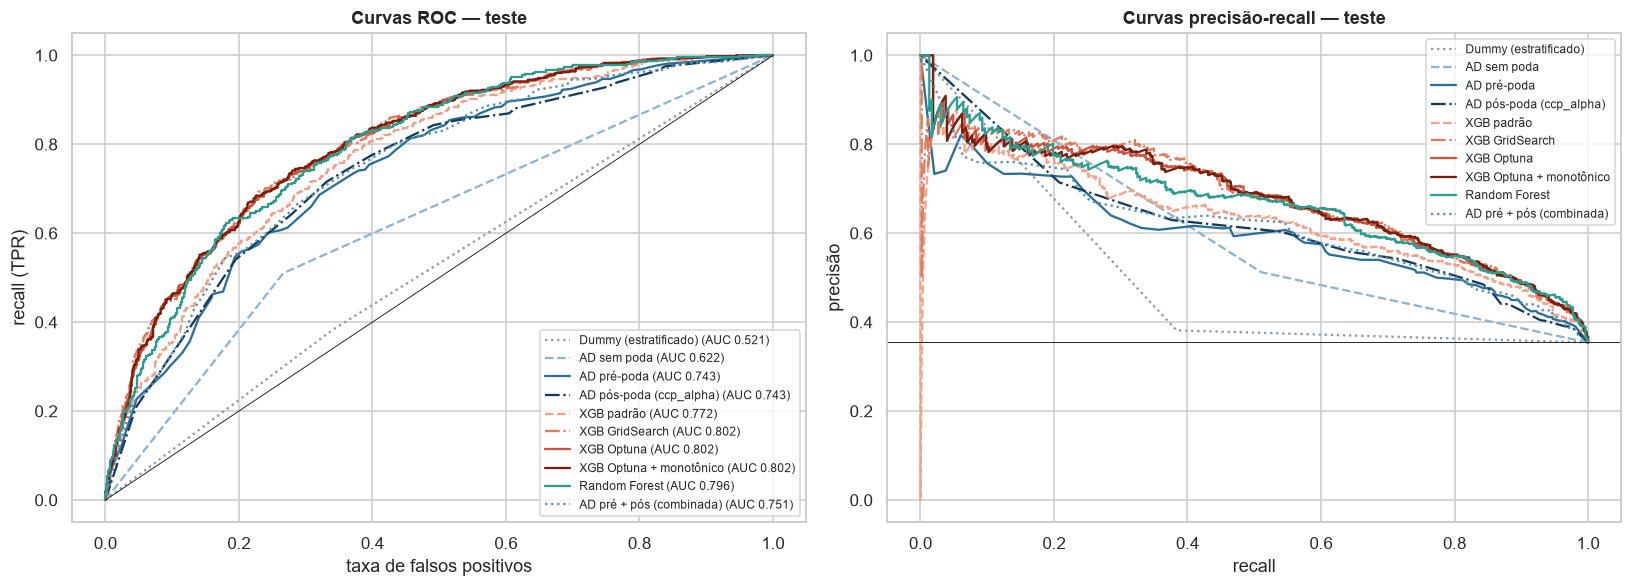

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
estilos = {"Dummy (estratificado)": (COR["base"], ":"), "AD sem poda": ("#90b4ce", "--"), "AD pré-poda": (COR["ad"], "-"),
           "AD pós-poda (ccp_alpha)": ("#123c5a", "-."), "XGB padrão": ("#f2a28b", "--"), "XGB GridSearch": ("#e07a5f", "-."),
           "XGB Optuna": (COR["xgb"], "-"), "XGB Optuna + monotônico": ("#7a1f0f", "-"),
           "Random Forest": (COR["ok"], "-"), "AD pré + pós (combinada)": ("#5c8db3", ":")}
for n, p in PROBA_TESTE.items():
    cor, ls = estilos[n]
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, color=cor, ls=ls, label=f"{n} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, color=cor, ls=ls, label=n)
axes[0].plot([0, 1], [0, 1], color="k", lw=.6); axes[0].set(xlabel="taxa de falsos positivos", ylabel="recall (TPR)", title="Curvas ROC — teste")
axes[1].axhline(y_test.mean(), color="k", lw=.6); axes[1].set(xlabel="recall", ylabel="precisão", title="Curvas precisão-recall — teste")
axes[0].legend(fontsize=8, loc="lower right"); axes[1].legend(fontsize=8)
plt.tight_layout(); salvar("roc_pr_teste"); plt.show()

### 9.1 H4 — O XGBoost é melhor que a árvore podada? Intervalos de confiança por bootstrap

Uma diferença no teste pode ser sorte da amostra. Reamostramos o teste 2.000 vezes (com reposição, **pareado**: os
mesmos clientes para os dois modelos) e calculamos IC 95% de cada métrica e da diferença XGB − AD.

In [31]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
thr_ad, thr_xgb = LIMIARES[AD_FINAL_NOME][crit_rec], LIMIARES[XGB_FINAL_NOME][crit_rec]
pa, px = PROBA_TESTE[AD_FINAL_NOME], PROBA_TESTE[XGB_FINAL_NOME]
boot = {k: [] for k in ["AUC AD", "AUC XGB", "ΔAUC", "recall AD", "recall XGB", "Δrecall", "precisão AD", "precisão XGB", "Δprecisão"]}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max(): continue
    a1, a2 = roc_auc_score(yt[i], pa[i]), roc_auc_score(yt[i], px[i])
    r1, r2 = recall_score(yt[i], pa[i] >= thr_ad), recall_score(yt[i], px[i] >= thr_xgb)
    p1, p2 = precision_score(yt[i], pa[i] >= thr_ad), precision_score(yt[i], px[i] >= thr_xgb)
    for k, v in zip(boot, [a1, a2, a2 - a1, r1, r2, r2 - r1, p1, p2, p2 - p1]): boot[k].append(v)
ic = pd.DataFrame({k: {"média": np.mean(v), "IC95% inf": np.percentile(v, 2.5), "IC95% sup": np.percentile(v, 97.5)}
                   for k, v in boot.items()}).T.round(3)
ic["IC da diferença contém 0?"] = ["" if not k.startswith("Δ") else ("sim" if r["IC95% inf"] <= 0 <= r["IC95% sup"] else "não")
                                    for k, r in ic.iterrows()]
ic

,média,IC95% inf,IC95% sup,IC da diferença contém 0?
AUC AD,0.751,0.726,0.777,
AUC XGB,0.802,0.780,0.824,
ΔAUC,0.051,0.035,0.066,não
recall AD,0.855,0.824,0.883,
recall XGB,0.815,0.783,0.847,
Δrecall,-0.040,-0.071,-0.010,não
precisão AD,0.466,0.434,0.498,
precisão XGB,0.545,0.508,0.580,
Δprecisão,0.079,0.060,0.099,não


## 10. Análise de overfitting

### 10.1 Gap treino × teste (limiar 0,5)

,acurácia treino,acurácia teste,gap acurácia,recall treino,recall teste,gap recall,AUC treino,AUC teste,gap AUC
modelo,,,,,,,,,
Dummy (estratificado),0.536,0.561,-0.025,0.350,0.384,-0.034,0.494,0.521,-0.027
AD sem poda,1.000,0.654,0.346,1.000,0.510,0.490,1.000,0.622,0.378
AD pré-poda,0.716,0.666,0.051,0.814,0.735,0.078,0.821,0.743,0.078
AD pós-poda (ccp_alpha),0.686,0.663,0.023,0.794,0.775,0.019,0.778,0.743,0.035
XGB padrão,0.946,0.723,0.222,0.887,0.541,0.347,0.991,0.772,0.219
XGB GridSearch,0.750,0.746,0.004,0.553,0.548,0.004,0.819,0.802,0.017
XGB Optuna,0.733,0.729,0.004,0.733,0.720,0.012,0.813,0.802,0.012
XGB Optuna + monotônico,0.732,0.728,0.004,0.731,0.718,0.013,0.811,0.802,0.009
Random Forest,0.807,0.741,0.066,0.614,0.514,0.100,0.891,0.796,0.094


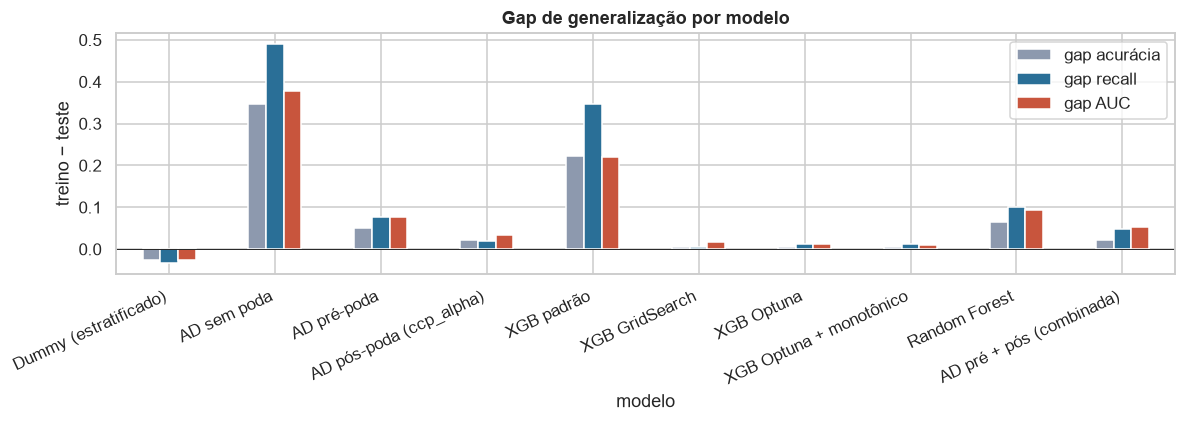

In [32]:
gap = []
for n in MODELOS:
    mtr, mte = metrics_at(y_train, PROBA_TREINO[n]), metrics_at(y_test, PROBA_TESTE[n])
    gap.append({"modelo": n, "acurácia treino": mtr["accuracy"], "acurácia teste": mte["accuracy"],
                "gap acurácia": mtr["accuracy"] - mte["accuracy"], "recall treino": mtr["recall"], "recall teste": mte["recall"],
                "gap recall": mtr["recall"] - mte["recall"], "AUC treino": mtr["roc_auc"], "AUC teste": mte["roc_auc"],
                "gap AUC": mtr["roc_auc"] - mte["roc_auc"]})
gap = pd.DataFrame(gap).set_index("modelo").round(3)
display(gap.style.background_gradient(subset=["gap acurácia", "gap recall", "gap AUC"], cmap="Reds").format("{:.3f}"))

fig, ax = plt.subplots(figsize=(11, 4))
gap[["gap acurácia", "gap recall", "gap AUC"]].plot.bar(ax=ax, color=["#8d99ae", COR["ad"], COR["xgb"]])
ax.set(ylabel="treino − teste", title="Gap de generalização por modelo"); ax.axhline(0, color="k", lw=.6)
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); salvar("gap_overfitting"); plt.show()

### 10.2 Curvas de aprendizado

Treinamos com frações crescentes do treino (CV 5-fold). Curvas que convergem com gap pequeno indicam bom equilíbrio
viés-variância; um gap grande e persistente indica variância (memorização); curvas baixas e juntas indicam viés.

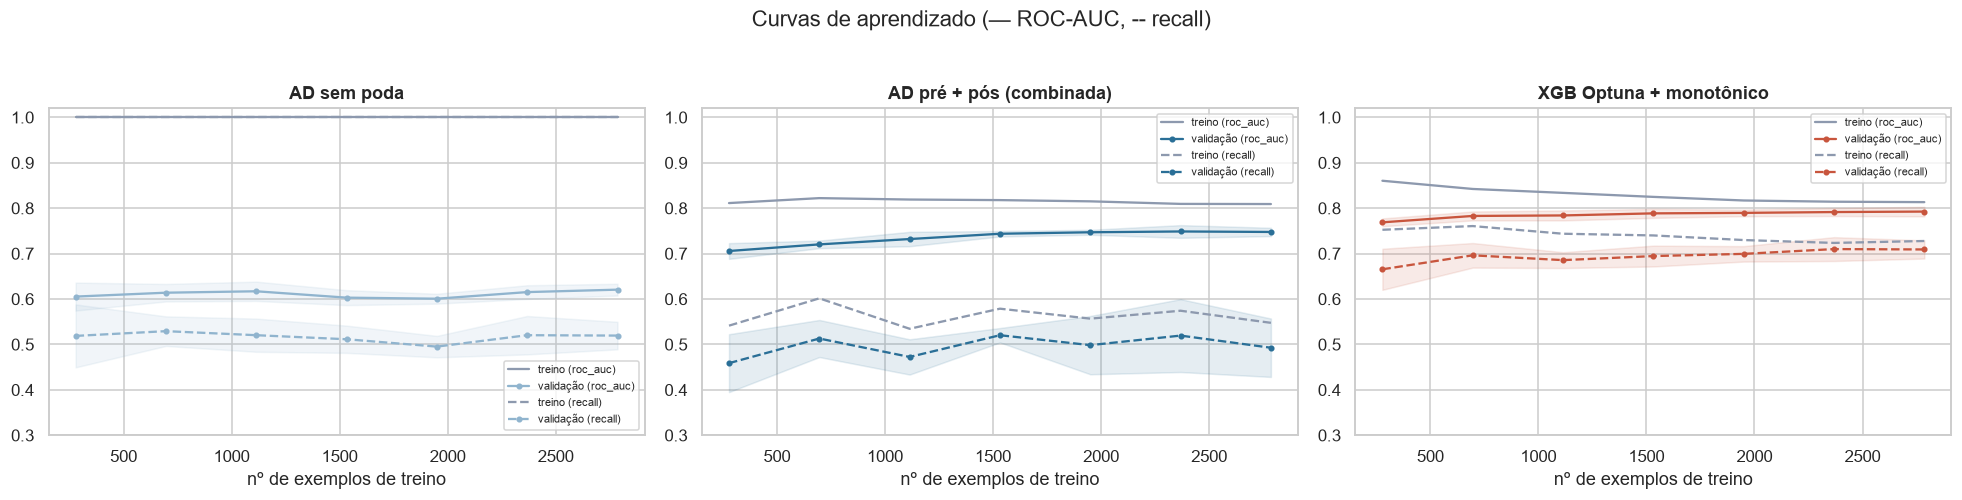

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
tamanhos = np.linspace(0.1, 1.0, 7)
for ax, (n, est, cor) in zip(axes, [("AD sem poda", make_pipeline(DecisionTreeClassifier(random_state=SEED), memory=CACHE), "#90b4ce"),
                                     (AD_FINAL_NOME, AD_FINAL, COR["ad"]), (XGB_FINAL_NOME, XGB_FINAL, COR["xgb"])]):
    for metrica, ls in [("roc_auc", "-"), ("recall", "--")]:
        sz, tr, va = learning_curve(est, X_train, y_train, cv=CV, train_sizes=tamanhos, scoring=metrica, n_jobs=N_JOBS, shuffle=True, random_state=SEED)
        ax.plot(sz, tr.mean(1), ls=ls, color=COR["base"], label=f"treino ({metrica})")
        ax.plot(sz, va.mean(1), ls=ls, color=cor, marker="o", ms=3, label=f"validação ({metrica})")
        ax.fill_between(sz, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=cor, alpha=.12)
    ax.set(title=n, xlabel="nº de exemplos de treino", ylim=(0.3, 1.02)); ax.legend(fontsize=7)
plt.suptitle("Curvas de aprendizado (— ROC-AUC, -- recall)", y=1.03); plt.tight_layout(); salvar("curvas_aprendizado"); plt.show()

## 11. Relevância de variáveis nos dois modelos

Importâncias internas (impureza/ganho) são enviesadas para atributos contínuos com muitos cortes possíveis. Por isso
complementamos com **importância por permutação no teste** (queda de ROC-AUC ao embaralhar o atributo), calculada
sobre o `Pipeline` completo e nos atributos **originais**.

As três janelas de suporte (30/60/90 dias) são **permutadas juntas**: embaralhá-las separadamente criaria clientes
impossíveis (ex.: mais chamados em 30 do que em 90 dias) — o próprio pipeline do miniprojeto 1 rejeita esse caso.

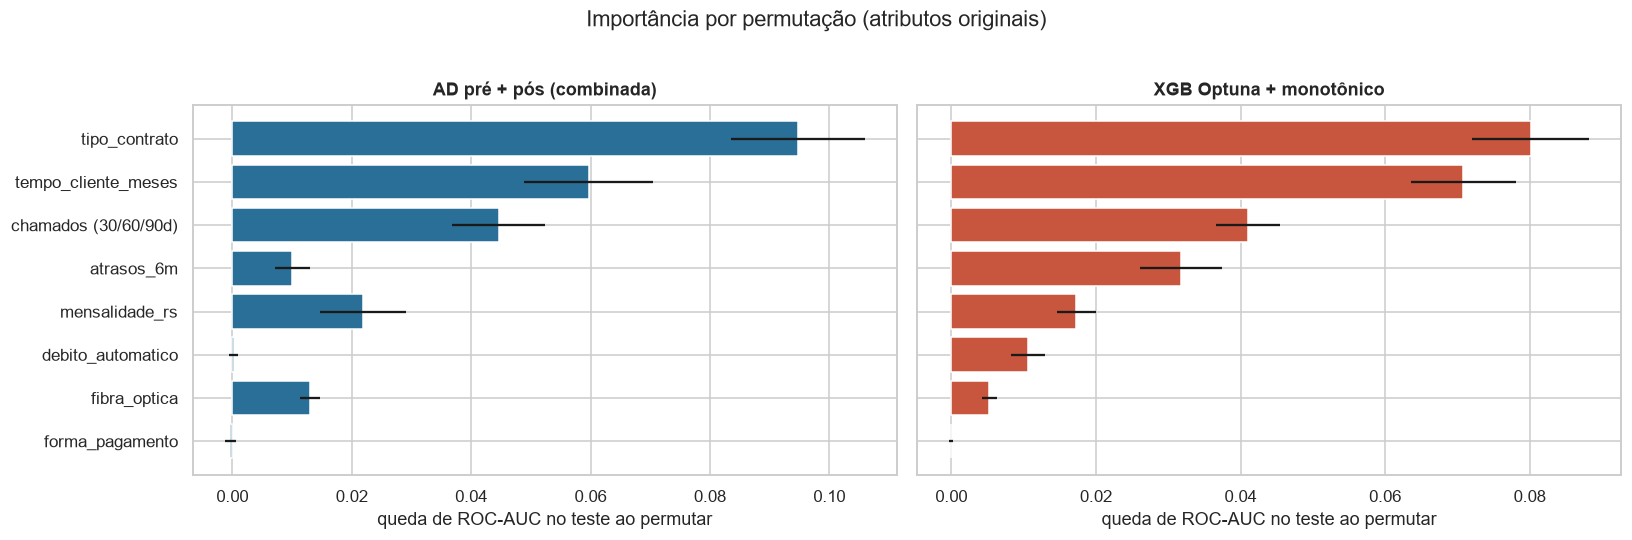

,AD — impureza,XGB — gain,AD — permutação,XGB — permutação,AD — impureza (posição),XGB — gain (posição),AD — permutação (posição),XGB — permutação (posição)
tipo_contrato,0.274,0.325,0.095,0.080,2,1,1,1
tempo_cliente_meses,0.238,0.109,0.060,0.071,3,3,2,2
chamados (30/60/90d),0.290,0.222,0.045,0.041,1,2,3,3
atrasos_6m,0.060,0.086,0.010,0.032,5,5,6,4
mensalidade_rs,0.116,0.062,0.022,0.017,4,6,4,5
debito_automatico,0.003,0.048,0.000,0.011,8,8,7,6
fibra_optica,0.014,0.096,0.013,0.005,6,4,5,7
forma_pagamento,0.005,0.052,-0.000,-0.000,7,7,8,8


In [34]:
GRUPOS = {"chamados (30/60/90d)": ["chamados_30d", "chamados_60d", "chamados_90d"]}
GRUPOS.update({c: [c] for c in FEATURE_COLUMNS if not c.startswith("chamados_")})

def importancia_permutacao(modelo, X, y, n_rep=15, seed=SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, modelo.predict_proba(X)[:, 1])
    res = {}
    for g, cols in GRUPOS.items():
        quedas = []
        for _ in range(n_rep):
            Xp = X.copy(); idx = rng.permutation(len(X))
            Xp[cols] = X[cols].to_numpy()[idx]
            quedas.append(base - roc_auc_score(y, modelo.predict_proba(Xp)[:, 1]))
        res[g] = (np.mean(quedas), np.std(quedas))
    return pd.DataFrame(res, index=["queda_auc", "dp"]).T

perm = {n: importancia_permutacao(m, X_test, y_test) for n, m in FINAIS.items()}
ordem = perm[XGB_FINAL_NOME]["queda_auc"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, (n, df), cor in zip(axes, perm.items(), [COR["ad"], COR["xgb"]]):
    df = df.loc[ordem]; ax.barh(df.index, df["queda_auc"], xerr=df["dp"], color=cor)
    ax.set(title=f"{n}", xlabel="queda de ROC-AUC no teste ao permutar")
plt.suptitle("Importância por permutação (atributos originais)", y=1.02); plt.tight_layout(); salvar("importancia_permutacao"); plt.show()

def para_original(serie):
    s = serie.copy(); s.index = [("chamados (30/60/90d)" if i.startswith("chamados_") or i in ("aceleracao_suporte", "chamados_61_90d") else agrupar(i)) for i in s.index]
    s = s.groupby(level=0).sum(); return s / s.sum()

ranking = pd.DataFrame({
    "AD — impureza": para_original(imp_ad), "XGB — gain": para_original(imp_xgb["gain"]),
    "AD — permutação": perm[AD_FINAL_NOME]["queda_auc"], "XGB — permutação": perm[XGB_FINAL_NOME]["queda_auc"],
}).fillna(0)
posicoes = ranking.rank(ascending=False).astype(int).add_suffix(" (posição)")
ranking_final = pd.concat([ranking.round(3), posicoes], axis=1).sort_values("XGB — permutação (posição)")
ranking_final.to_csv(REPORTS / "ranking_importancia.csv")
ranking_final

## 12. Resumo consolidado e exportação

In [35]:
cv_final = mostrar(RESULTADOS_CV)
cv_final.to_csv(REPORTS / "resultados_validacao_cruzada.csv")
hiper = {"AD pré-poda": {k: (None if v is None else v) for k, v in params_pre.items()},
         "AD pós-poda": {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in params_pos.items()},
         "XGB GridSearch": {k: float(v) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, (np.integer,)) else v for k, v in params_grid.items()},
         "AD combinada": {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in params_comb.items()},
         "Random Forest": params_rf,
         "XGB Optuna": params_optuna, "XGB monotonic_constraints": monotonia,
         "modelos finais": {"AD": AD_FINAL_NOME, "XGB": XGB_FINAL_NOME},
         "limiares (OOF treino)": {n: {k: float(v) for k, v in LIMIARES[n].items() if not k.startswith("_")} for n in FINAIS}}
(REPORTS / "melhores_hiperparametros.json").write_text(json.dumps(hiper, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

final = teste_thr[teste_thr["critério do limiar"].isin(["padrão 0,5", crit_rec])][["modelo", "critério do limiar", "threshold", "recall", "precision", "f1", "roc_auc", "tp", "fp", "fn"]]
print("Validação cruzada (treino):"); display(cv_final)
print("Teste — modelos finais:"); display(final.round(3))
print("Arquivos em reports/:", sorted(p.name for p in REPORTS.rglob("*") if p.is_file()))

Validação cruzada (treino):


,val_recall,val_precision,val_f1,val_f2,val_roc_auc,val_pr_auc,treino_recall,treino_roc_auc,gap_recall,gap_auc
modelo,,,,,,,,,,
Dummy (sempre não-churn),0.000,0.000,0.000,0.000,0.500,0.354,0.000,0.500,0.000,0.000
Dummy (sempre churn),1.000,0.354,0.523,0.733,0.500,0.354,1.000,0.500,0.000,0.000
Dummy (aleatório estratificado),0.335,0.350,0.342,0.338,0.497,0.353,0.358,0.505,0.023,0.008
AD sem poda,0.491,0.489,0.490,0.491,0.604,0.421,1.000,1.000,0.509,0.396
XGB padrão,0.524,0.585,0.553,0.535,0.747,0.609,0.929,0.996,0.405,0.249
AD pré-poda,0.718,0.541,0.616,0.673,0.758,0.614,0.780,0.818,0.062,0.059
AD pós-poda (ccp_alpha),0.725,0.535,0.615,0.676,0.752,0.587,0.756,0.780,0.030,0.028
AD pré + pós (combinada),0.474,0.611,0.533,0.496,0.748,0.609,0.533,0.809,0.059,0.061
XGB GridSearch,0.527,0.662,0.586,0.549,0.792,0.671,0.550,0.823,0.023,0.031


Teste — modelos finais:


,modelo,critério do limiar,threshold,recall,precision,f1,roc_auc,tp,fp,fn
0,AD pré + pós (combinada),"padrão 0,5",0.500,0.544,0.625,0.582,0.751,288,173,241
1,AD pré + pós (combinada),recall ≥ 80%,0.243,0.854,0.465,0.603,0.751,452,519,77
3,XGB Optuna + monotônico,"padrão 0,5",0.500,0.718,0.597,0.652,0.802,380,257,149
4,XGB Optuna + monotônico,recall ≥ 80%,0.412,0.815,0.545,0.653,0.802,431,360,98


Arquivos em reports/: ['ad_arvore_topo.png', 'ad_curva_complexidade.png', 'ad_erro_vs_nos.png', 'ad_importancia.png', 'ad_pospoda_ccp_alpha.png', 'ad_prepoda_heatmap.png', 'curvas_aprendizado.png', 'gap_overfitting.png', 'importancia_permutacao.png', 'limiar_trade_off.png', 'matrizes_confusao_teste.png', 'melhores_hiperparametros.json', 'metricas_teste_limiar_05.csv', 'metricas_teste_limiares.csv', 'optuna_trials.csv', 'ranking_importancia.csv', 'regras_arvore_folhas.csv', 'regras_arvore_topo.csv', 'resultados_validacao_cruzada.csv', 'roc_pr_teste.png', 'xgb_importancia.png', 'xgb_optuna.png', 'xgb_tradeoff_lr_n_estimators.png']


## 13. Conclusões

**Protocolo.** Split 70/30 estratificado antes de qualquer ajuste; imputação KNN, moda e one-hot dentro do `Pipeline`,
reajustados em cada fold; teste usado uma única vez. A auditoria mostrou que os folds pré-calculados reproduzem o
`Pipeline` exatamente, e as métricas do teste coincidem com as da validação cruzada (XGB: ROC-AUC 0,793 na CV, 0,802
no teste), sinal de que não houve vazamento nem otimismo da busca.

**Métrica.** Com 35,4% de churn, o classificador trivial "sempre churn" tem F2 = 0,733, mais que modelos razoáveis.
Otimizar F2 levou a modelos degenerados (recall 0,96 / precisão 0,44). Separamos as decisões: hiperparâmetros por
**PR-AUC** e recall pelo **limiar** escolhido em previsões *out-of-fold* do treino (meta ≥ 80%).

**Árvore de Decisão.** Sem poda: 916 folhas, AUC 1,00 no treino e 0,60 na validação (overfitting). O gráfico
erro × nº de nós da aula se reproduz: mínimo de 32,1% de erro com 29 nós contra 35,3% na árvore completa (1.981 nós).
Pré-poda (PR-AUC 0,614, 72 folhas), pós-poda por `ccp_alpha` (0,587, 15 folhas) e a combinação `max_depth` +
`ccp_alpha` recomendada na aula (0,609, 51 folhas) ficaram próximas; pela navalha de Occam escolhemos a combinada.
Gini e entropia deram resultados praticamente iguais, como a aula antecipa. As regras mostram que o risco se concentra
em **contrato mensal + atrito com o suporte + pouco tempo de casa** (ex.: mensal, ≥ 3 chamados, ≥ 2 atrasos e até 10
meses → 92% de churn) e que contratos anuais/bienais com mais de 3 anos e poucos chamados praticamente não cancelam.
Identificamos que, com `class_weight="balanced"`, os valores internos da árvore inflam a taxa de churn; as regras
usam as contagens reais.

**XGBoost.** η × nº de árvores é aproximadamente constante no ótimo (η 0,005 → 1.581 árvores; η 0,3 → 17), com o
mesmo erro mínimo; η alto sobreajusta rápido depois do ótimo. GridSearchCV (192 combinações, PR-AUC 0,671) e Optuna
(120 tentativas, 10 hiperparâmetros contínuos, 0,670) empataram e convergiram para a mesma receita (árvores de
profundidade 2, η baixo, muitas árvores) — o teto parece ser o sinal da base. As restrições monotônicas não custaram
desempenho (0,668 → 0,670) e reduziram o gap; foram adotadas. A Random Forest da aula quase empata no ranking
(0,666), mas sobreajusta ~6× mais (gap de AUC 0,120 × 0,020).

**Hipóteses sem efeito.** Mediana × KNN e atributos derivados mudaram a PR-AUC menos que o desvio entre folds; mantivemos
a configuração mais simples. O KNN reconstruía melhor os ausentes no miniprojeto 1, mas isso não virou previsão melhor.

**Teste (limiar para recall ≥ 80%).**

| Modelo | Limiar | Recall | Precisão | ROC-AUC | PR-AUC | VP | FP | FN |
|---|---|---|---|---|---|---|---|---|
| Árvore pré + pós-poda | 0,243 | 0,854 | 0,465 | 0,751 | 0,604 | 452 | 519 | 77 |
| XGB Optuna + monotônico | 0,412 | 0,815 | 0,545 | 0,802 | 0,678 | 431 | 360 | 98 |

Bootstrap pareado (2.000 reamostragens): ΔROC-AUC = +0,051 [0,035; 0,066] e Δprecisão = +7,9 pp [6,0; 9,9] a favor do
XGBoost; a árvore teve recall 4 pp maior porque seu limiar ficou mais agressivo — diferença que se ajusta pelo limiar.
O gap treino − teste caiu de 0,378 (árvore sem poda) para 0,054 (árvore final) e 0,009 (XGBoost final). Os dois modelos
concordam no top 3 de importância: **tipo de contrato, tempo de cliente e chamados ao suporte**.

**Recomendação.** XGBoost com restrições monotônicas para priorizar a ação de retenção (cada 100 ofertas alcançam ~54
churners, contra ~47 da árvore) e a árvore podada para explicar e orientar as ações (migração de plano mensal para
anual, tratamento da causa dos chamados).

**Limitações.** Base sintética com um único corte temporal; custo FN = 5 × FP é hipótese a calibrar com o negócio;
validar em cortes futuros e tratar Early Churn (clientes com menos de 60 dias) em um modelo próprio.